# 08 · Web 后端实战（员工管理）


来源：[飞书讲义《08-后端Web实战(员工管理)》](https://heuqqdmbyk.feishu.cn/wiki/XXQTwBpWLiFDzjkpXShcXt8lnYg)。整理日期：2026-09-28。

本章按讲义顺序保留原文、72 段原代码、48 张配图和 4 张嵌入表格；勘误与补充就近标注。讲义中的代码是逐步迭代的同一项目，多个阶段的同名类不能直接拼接。第 4、5 节把表关系、联表查询和员工条件分页串成完整请求链路，并给出可基于第 07 章项目跟练的最终版片段。

原图以内嵌附件保存，可离线阅读。SQL 需在 MySQL 客户端运行，Java/XML 需放到对应工程文件中，Notebook 的 Python 内核不执行这些示例；讲义中的课程推广未收录。


## 本章学习路线（补充）

第 07 章已经完成部门接口。本章要在员工列表里显示“所属部门”，因此先理解表之间的关系，再用 SQL 联查，最后将查询变成可筛选、可分页的 `GET /emps` 接口。

| 阶段 | 核心问题 | 关键知识 |
| --- | --- | --- |
| 表设计 | 一个员工属于哪个部门？ | 一对多、一对一、多对多，物理/逻辑外键 |
| SQL | 无部门员工是否保留？ | 内连接、外连接、子查询 |
| 接口 | 数据怎样按页返回？ | `total`、`rows`、`LIMIT`、PageHelper |
| 筛选 | 可选条件如何组合？ | 请求参数对象、MyBatis `<if>`、`<where>` |

本章只做到**员工列表查询**。员工新增、修改、删除属于后续课程章节，不在这里预先扩写。


实现了部门管理的功能之后，接下来我们再来实现员工管理的功能。

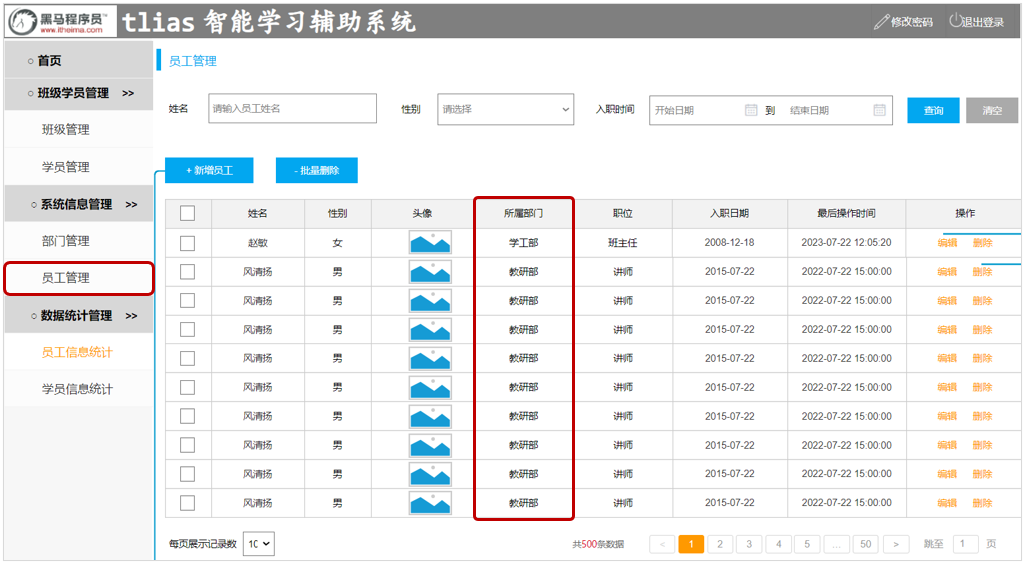

从页面原型中，我们可以看到，在查询员工信息的时候，除了要展示 姓名、性别、头像、职位、入职日期、最后操作时间这些员工信息外，还要展示出所属部门，那此时就需要从两张表中查询数据，一张是部门表，一张是员工表，此时就会涉及到多表操作。 所以今天的课程内容如下：

> 课程内容：
> 
> - 多表关系
> - 多表查询
> - 员工列表查询


## 1 多表关系

项目开发中，在进行数据库表结构设计时，会根据业务需求及业务模块之间的关系，分析并设计表结构，由于业务之间相互关联，所以各个表结构之间也存在着各种联系，基本上分为三种：

- 一对多(多对一)
- 多对多
- 一对一


### 1.1 一对多

- 场景：部门与员工的关系（一个部门下有多个员工）。
- 部门管理的页面原型：

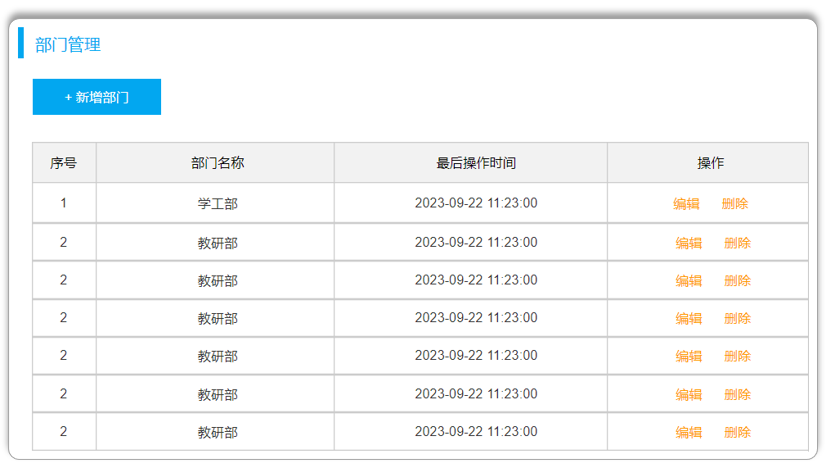

- 员工管理的页面原型：

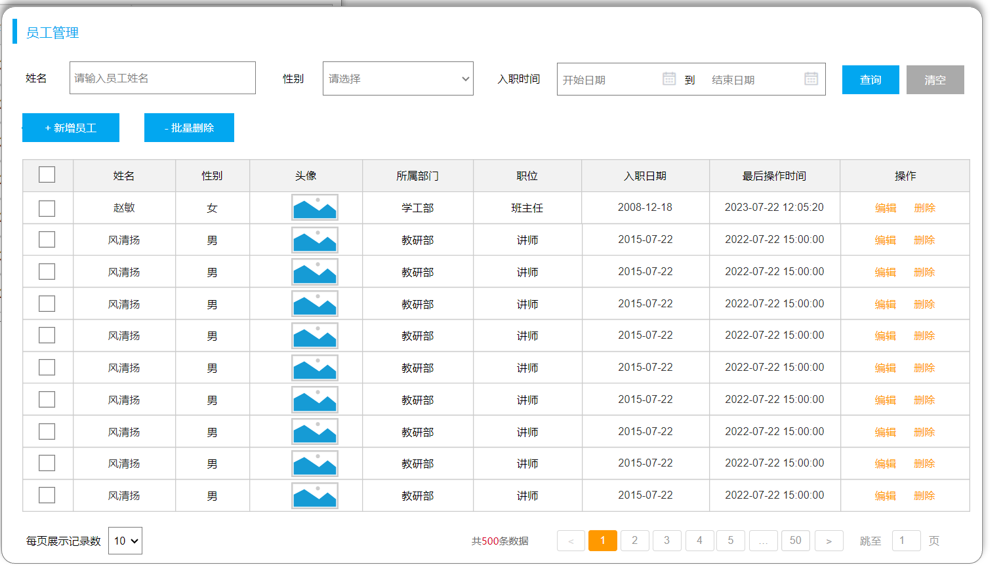

由于一个部门下，会关联多个员工。 而一个员工，是归属于某一个部门的 。那么此时，我们就需要在 <code>emp</code> 表中增加一个字段 <code>dept&#95;id</code> 来标识这个员工属于哪一个部门，<code>dept&#95;id</code> 关联的是 <code>dept</code> 的 <code>id</code> 。 如下所示：

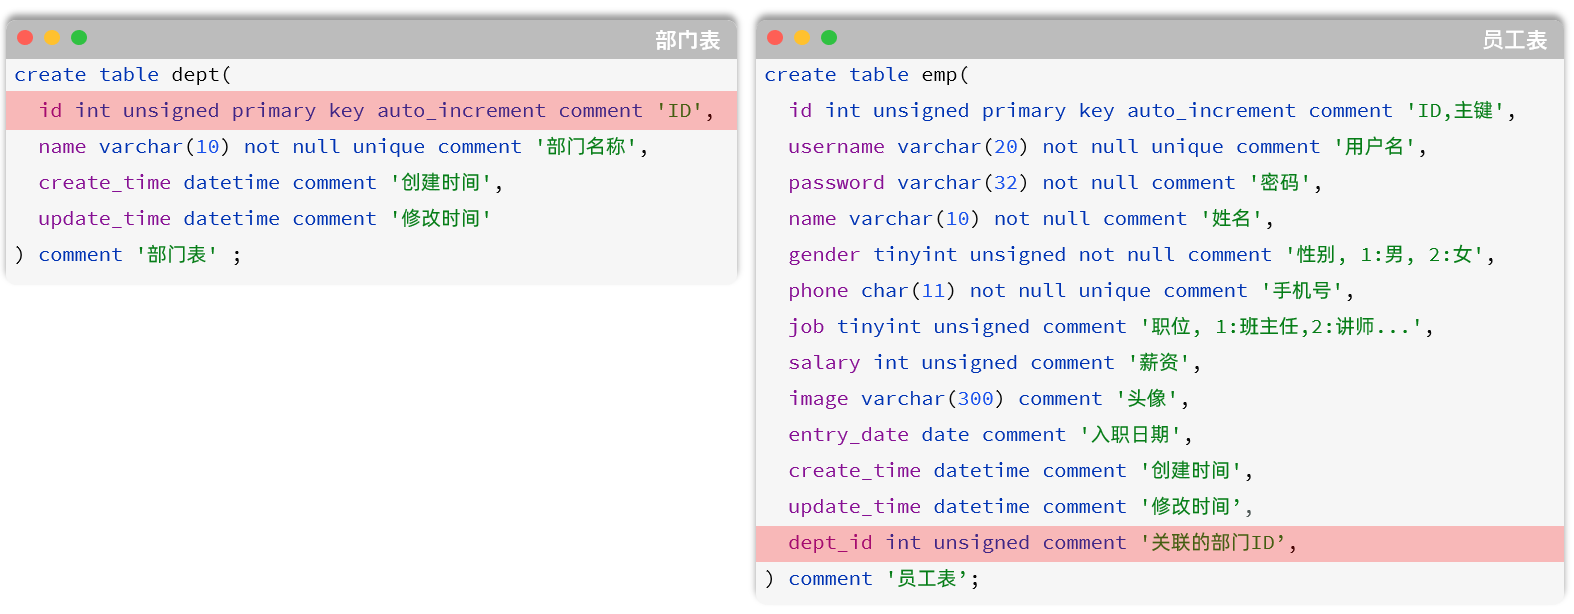

上述的 <code>emp</code> 员工表的 <code>dept&#95;id</code> 字段，关联的是 <code>dept</code> 部门表的 <code>id</code> 。部门表是一的一方，也称为<strong>父表</strong>，员工表是多的一方，称之为<strong>子表</strong>。

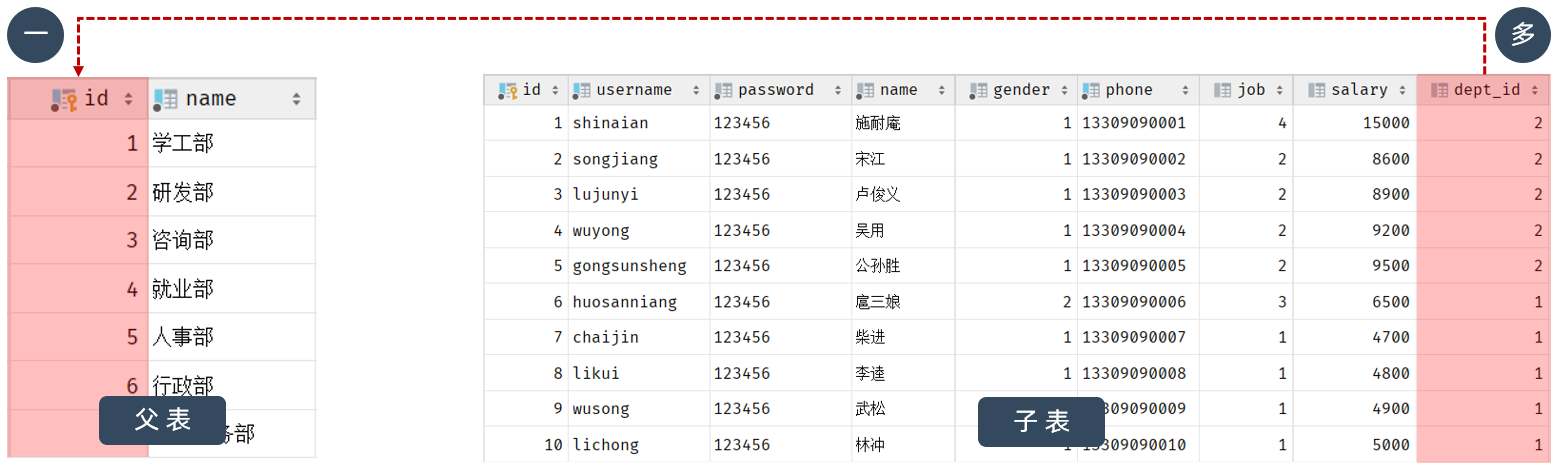

那接下来，我们就可以将上述的两张表创建出来。具体的SQL语句如下：

````sql
CREATE TABLE dept (
  id int unsigned PRIMARY KEY AUTO_INCREMENT COMMENT 'ID, 主键',
  name varchar(10) NOT NULL UNIQUE COMMENT '部门名称',
  create_time datetime DEFAULT NULL COMMENT '创建时间',
  update_time datetime DEFAULT NULL COMMENT '修改时间'
) COMMENT '部门表';

INSERT INTO dept VALUES (1,'学工部','2024-09-25 09:47:40','2023-04-25 09:47:40'),
                      (2,'教研部','2024-09-25 09:47:40','2024-10-09 15:17:04'),
                      (3,'咨询部2','2024-09-25 09:47:40','2024-11-30 21:26:24'),
                      (4,'就业部','2024-09-25 09:47:40','2024-09-25 09:47:40'),
                      (5,'人事部','2024-09-25 09:47:40','2024-09-25 09:47:40'),
                      (6,'行政部','2024-11-30 20:56:37','2024-11-30 20:56:37');

create table emp(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) not null unique comment '用户名',
    password varchar(50) default '123456' comment '密码',
    name varchar(10) not null comment '姓名',
    gender tinyint unsigned not null comment '性别, 1:男, 2:女',
    phone char(11) not null unique comment '手机号',
    job tinyint unsigned comment '职位, 1 班主任, 2 讲师 , 3 学工主管, 4 教研主管, 5 咨询师',
    salary int unsigned comment '薪资',
    image varchar(300) comment '头像',
    entry_date date comment '入职日期',
    dept_id int unsigned comment '部门ID',
    create_time datetime comment '创建时间',
    update_time datetime comment '修改时间'
) comment '员工表';


INSERT INTO emp VALUES 
    (1,'shinaian','123456','施耐庵',1,'13309090001',4,15000,'5.png','2000-01-01',2,'2023-10-20 16:35:33','2023-11-16 16:11:26'),
    (2,'songjiang','123456','宋江',1,'13309090002',2,8600,'01.png','2015-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:37'),
    (3,'lujunyi','123456','卢俊义',1,'13309090003',2,8900,'01.png','2008-05-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:39'),
    (4,'wuyong','123456','吴用',1,'13309090004',2,9200,'01.png','2007-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:41'),
    (5,'gongsunsheng','123456','公孙胜',1,'13309090005',2,9500,'01.png','2012-12-05',2,'2023-10-20 16:35:33','2023-10-20 16:35:43'),
    (6,'huosanniang','123456','扈三娘',2,'13309090006',3,6500,'01.png','2013-09-05',1,'2023-10-20 16:35:33','2023-10-20 16:35:45'),
    (7,'chaijin','123456','柴进',1,'13309090007',1,4700,'01.png','2005-08-01',1,'2023-10-20 16:35:33','2023-10-20 16:35:47'),
    (8,'likui','123456','李逵',1,'13309090008',1,4800,'01.png','2014-11-09',1,'2023-10-20 16:35:33','2023-10-20 16:35:49'),
    (9,'wusong','123456','武松',1,'13309090009',1,4900,'01.png','2011-03-11',1,'2023-10-20 16:35:33','2023-10-20 16:35:51'),
    (10,'linchong','123456','林冲',1,'13309090010',1,5000,'01.png','2013-09-05',1,'2023-10-20 16:35:33','2023-10-20 16:35:53'),
    (11,'huyanzhuo','123456','呼延灼',1,'13309090011',2,9700,'01.png','2007-02-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:55'),
    (12,'xiaoliguang','123456','小李广',1,'13309090012',2,10000,'01.png','2008-08-18',2,'2023-10-20 16:35:33','2023-10-20 16:35:57'),
    (13,'yangzhi','123456','杨志',1,'13309090013',1,5300,'01.png','2012-11-01',1,'2023-10-20 16:35:33','2023-10-20 16:35:59'),
    (14,'shijin','123456','史进',1,'13309090014',2,10600,'01.png','2002-08-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:01'),
    (15,'sunerniang','123456','孙二娘',2,'13309090015',2,10900,'01.png','2011-05-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:03'),
    (16,'luzhishen','123456','鲁智深',1,'13309090016',2,9600,'01.png','2010-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:05'),
    (17,'liying','12345678','李应',1,'13309090017',1,5800,'01.png','2015-03-21',1,'2023-10-20 16:35:33','2023-10-20 16:36:07'),
    (18,'shiqian','123456','时迁',1,'13309090018',2,10200,'01.png','2015-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:09'),
    (19,'gudasao','123456','顾大嫂',2,'13309090019',2,10500,'01.png','2008-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:11'),
    (20,'ruanxiaoer','123456','阮小二',1,'13309090020',2,10800,'01.png','2018-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:13'),
    (21,'ruanxiaowu','123456','阮小五',1,'13309090021',5,5200,'01.png','2015-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:15'),
    (22,'ruanxiaoqi','123456','阮小七',1,'13309090022',5,5500,'01.png','2016-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:17'),
    (23,'ruanji','123456','阮籍',1,'13309090023',5,5800,'01.png','2012-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:19'),
    (24,'tongwei','123456','童威',1,'13309090024',5,5000,'01.png','2006-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:21'),
    (25,'tongmeng','123456','童猛',1,'13309090025',5,4800,'01.png','2002-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:23'),
    (26,'yanshun','123456','燕顺',1,'13309090026',5,5400,'01.png','2011-01-01',3,'2023-10-20 16:35:33','2023-11-08 22:12:46'),
    (27,'lijun','123456','李俊',1,'13309090027',2,6600,'8.png','2004-01-01',2,'2023-10-20 16:35:33','2023-11-16 17:56:59'),
    (28,'lizhong','123456','李忠',1,'13309090028',5,5000,'6.png','2007-01-01',3,'2023-10-20 16:35:33','2023-11-17 16:34:22'),
    (30,'liyun','123456','李云',1,'13309090030',NULL,NULL,'01.png','2020-03-01',NULL,'2023-10-20 16:35:33','2023-10-20 16:36:31'),
    (36,'linghuchong','123456','令狐冲',1,'18809091212',2,6800,'1.png','2023-10-19',2,'2023-10-20 20:44:54','2023-11-09 09:41:04');
    
````

> **安全提醒：**下方初始化 SQL 是课程演示数据，含明文弱密码；只应在隔离的练习库运行。实际系统必须存储带盐的密码哈希，并禁止把 `password` 列返回给员工列表接口。`dept` 与第 07 章同名，已有数据时不要重复建表或直接覆盖。

> <strong>问题：一对多的表关系，在数据库层面该如何实现 ？</strong>
> 
> 在数据库表中多的一方，添加字段，来关联一的一方的主键 。


### 1.2 多表问题分析


#### 1.2.1 问题

表结构创建完毕后，我们看到两张表的数据分别为：

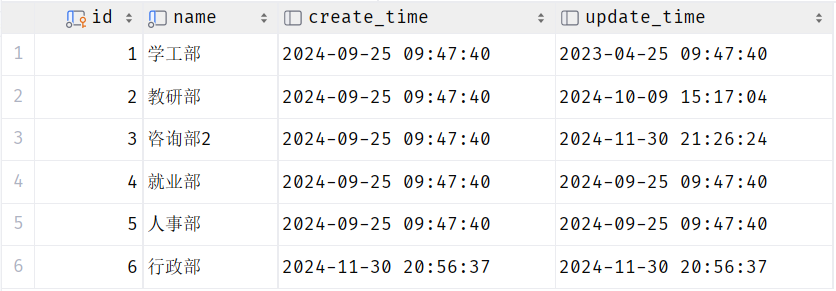

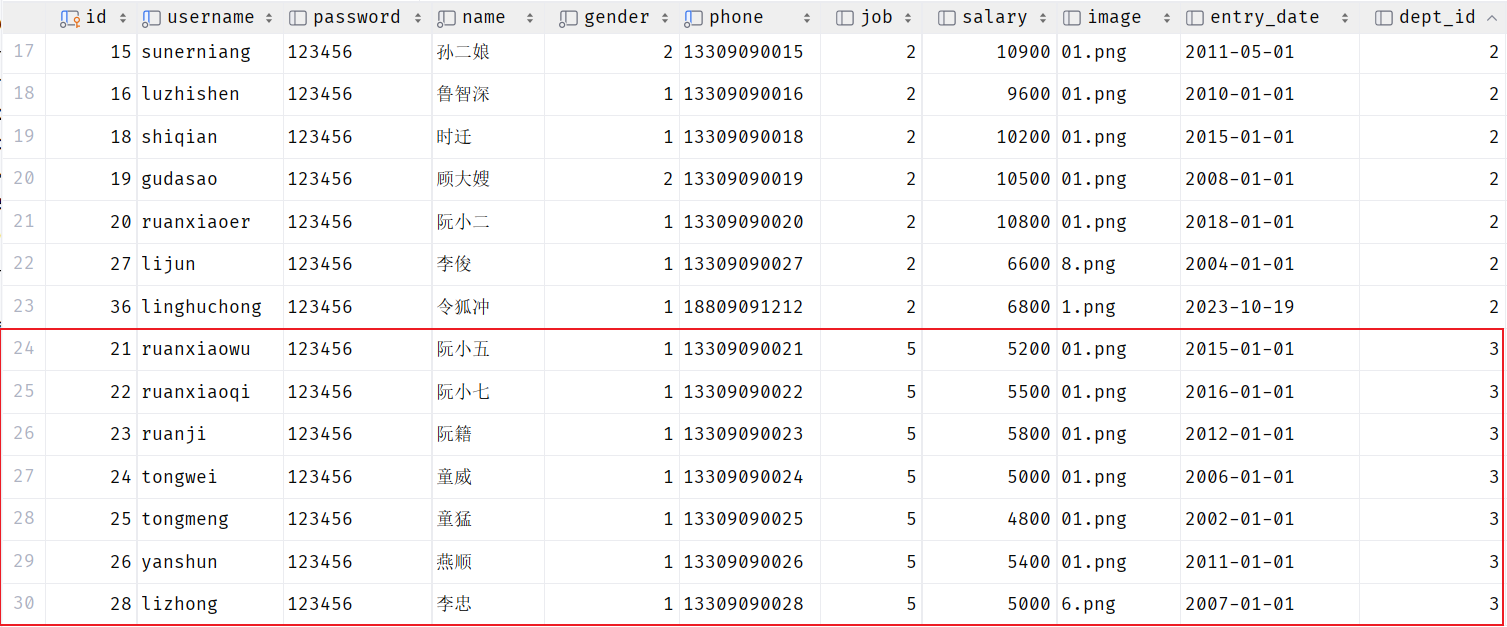

我们看到，在3号部门下，是关联的有7个员工。 当删除了3号部门后，数据变为：

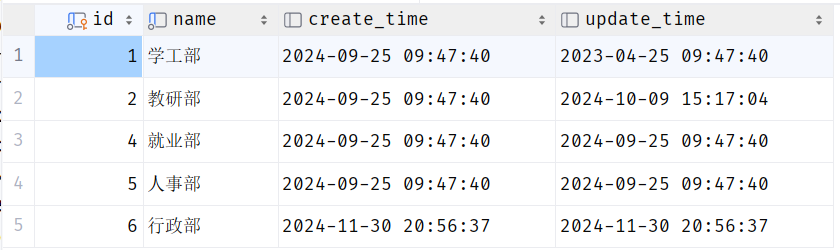

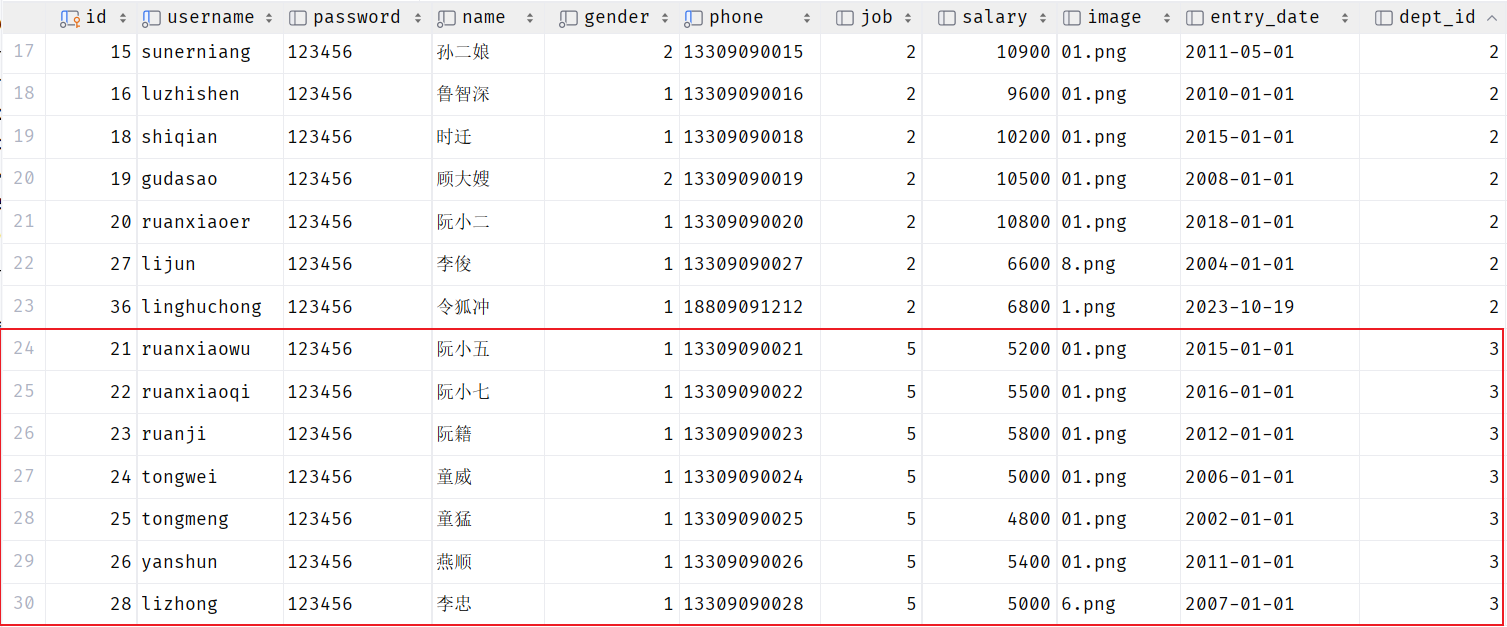

3号部门被删除了，但是依然还有7个员工是属于3号部门的。 此时：就出现数据的不完整、不一致了。


#### 1.2.2 分析

- 现象：部门数据可以直接删除，然而还有部分员工归属于该部门下，此时就出现了数据的不完整、不一致问题 。
- 原因：目前上述的两张表，在数据库层面，并未建立关联，所以是无法保证数据的一致性和完整性的 。
- 解决方案：想解决上述的问题呢，我们就可以通过数据库中的 <strong>外键约束</strong> 来解决。

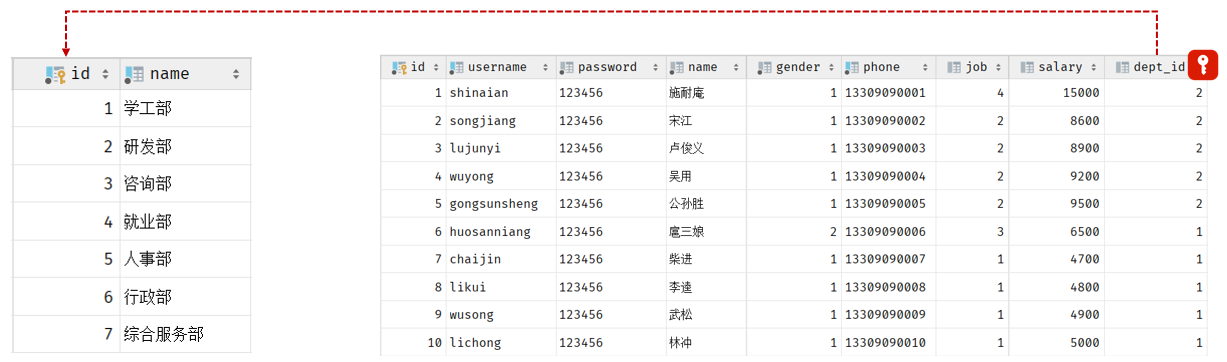

> <strong>外键约束：让两张表的数据建立连接，保证数据的一致性和完整性。 </strong>
> 
> <strong>对应的关键字：foreign key </strong>

外键约束的语法：

````sql
-- 创建表时指定
create table 表名(
        字段名    数据类型,
        ...
        [constraint]   [外键名称]  foreign  key (外键字段名)   references   主表 (主表列名)        
);


-- 建完表后，添加外键
alter table  表名  add constraint  外键名称  foreign key(外键字段名) references 主表(主表列名);
````

那接下来，我们就为员工表的dept&#95;id 建立外键约束，来关联部门表的主键。

当我们添加外键约束时，我们得保证当前数据库表中的数据是完整的。 所以，我们需要将之前删除掉的数据再添加回来。

<strong>方式1：通过SQL语句操作</strong>

````sql
-- 修改表： 添加外键约束
alter table emp  add  constraint  fk_dept_id  foreign key (dept_id)  references  dept(id);
````

<strong>方式2：</strong><strong>图形化界面操作</strong>

在左侧菜单栏，在emp表上右键，选择 <code>modify Table... (old UI)</code>

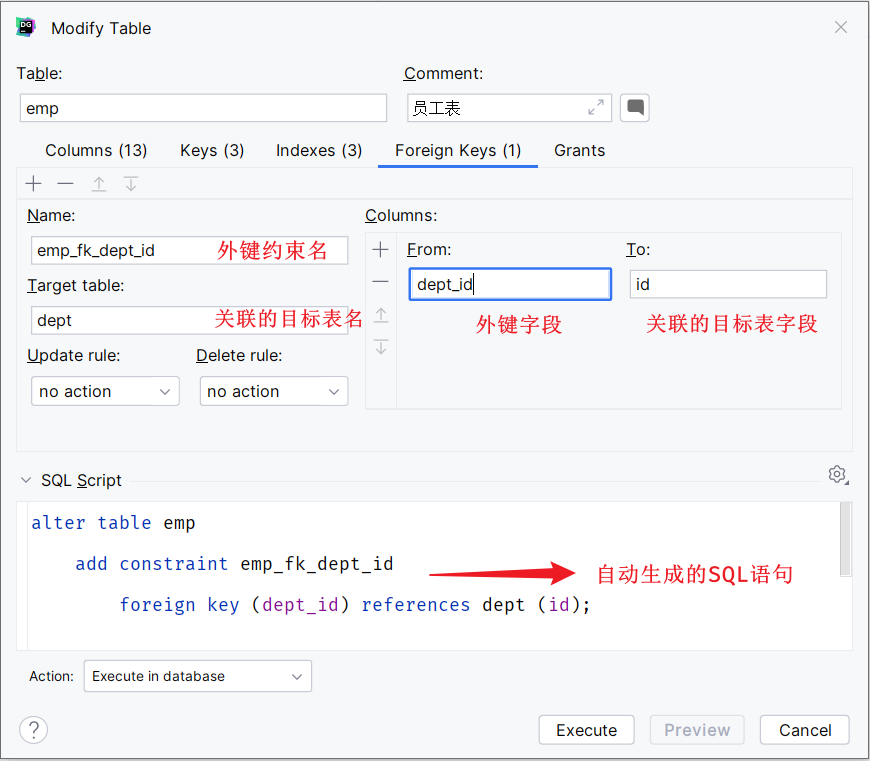

当我们添加了外键之后，再删除ID为3的部门，就会发现，此时数据库报错了，不允许删除。

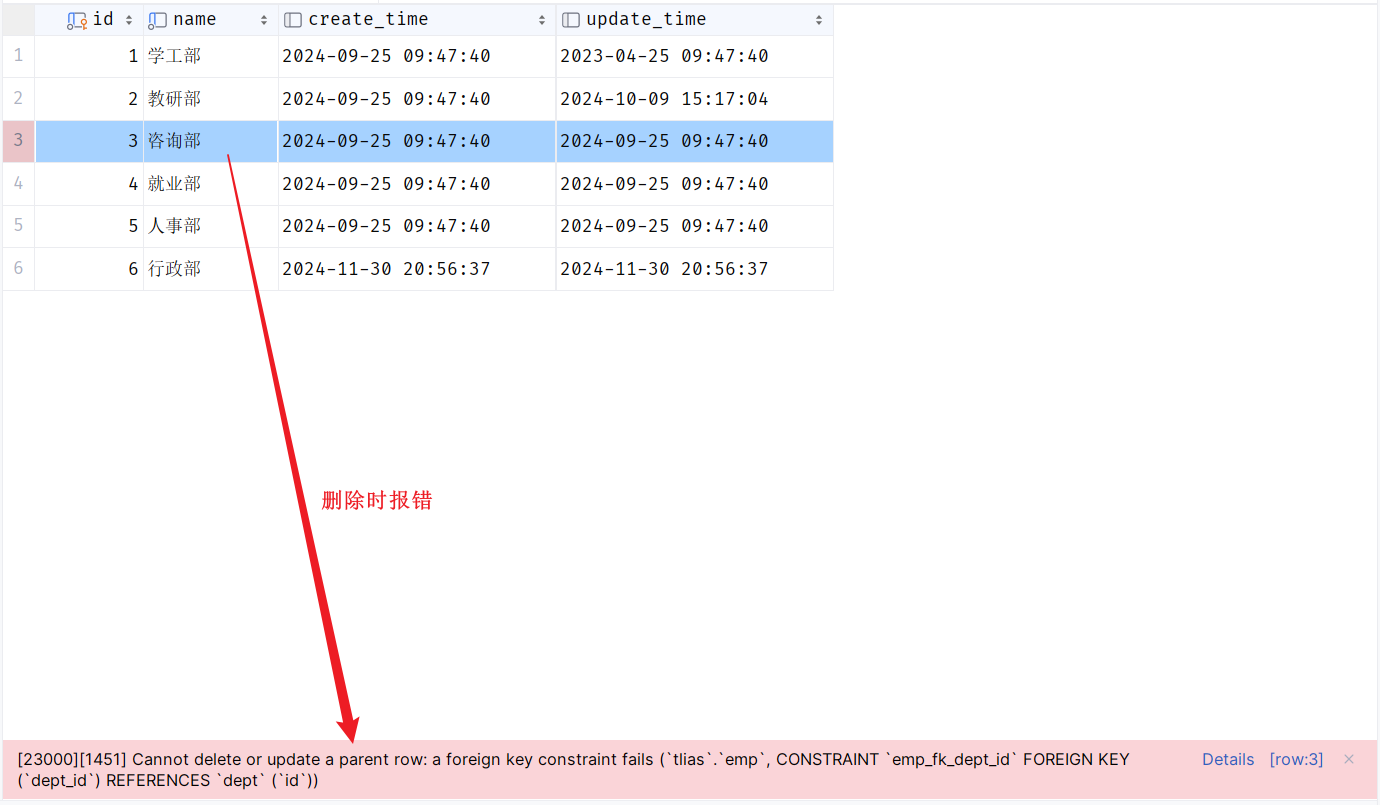

外键约束（foreign key）：保证了数据的完整性和一致性。


#### 1.2.3 物理外键与逻辑外键

**关系设计速记：**一对多把关联列放在“多”的一侧；一对一除了关联列，还要加 `UNIQUE` 保证至多一条；多对多用中间表，并建议对 `(student_id, course_id)` 加联合唯一约束，避免同一选课重复插入。`NOT NULL` 决定是否允许关联为空，与关系类型是两个问题。

- 物理外键

    - 概念：使用foreign key定义外键关联另外一张表。
    - 缺点：

        - 影响增、删、改的效率（需要检查外键关系）。
        - 仅用于单节点数据库，不适用于分布式、集群场景。
        - 容易引发数据库的死锁问题，消耗性能。

- 逻辑外键

    - 概念：在业务层逻辑中，解决外键关联。
    - 通过逻辑外键，就可以很方便的解决上述问题。

> 在现在的企业开发中，很少会使用物理外键，都是使用逻辑外键。 甚至在一些数据库开发规范中，会明确指出禁止使用物理外键 foreign key 
> 
> > **边界说明：**物理外键并非一律不适合企业开发。单库事务内，它能直接阻止孤儿记录；跨库、分片或异步写入时，数据库外键通常无法跨边界生效，需要业务校验、事务或补偿机制。是否使用应取决于部署结构、写入频率和一致性要求。逻辑外键本身只是普通列，不能自动保证引用完整性。


### 1.3 一对一

一对一关系表在实际开发中应用起来比较简单，通常是用来做单表的拆分，也就是将一张大表拆分成两张小表，将大表中的一些基础字段放在一张表当中，将其他的字段放在另外一张表当中，以此来提高数据的操作效率。

一对一的应用场景： 用户表(基本信息+身份信息)

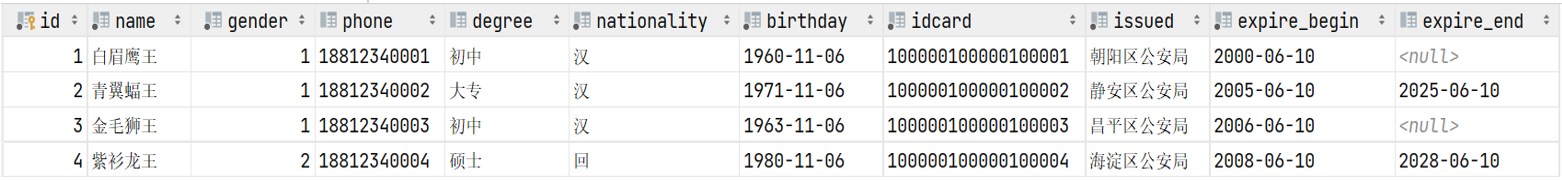

- 基本信息：用户的ID、姓名、性别、手机号、学历
- 身份信息：民族、生日、身份证号、身份证签发机关，身份证的有效期(开始时间、结束时间)

如果在业务系统当中，对用户的基本信息查询频率特别的高，但是对于用户的身份信息查询频率很低，此时出于提高查询效率的考虑，我就可以将这张大表拆分成两张小表，第一张表存放的是用户的基本信息，而第二张表存放的就是用户的身份信息。他们两者之间一对一的关系，一个用户只能对应一个身份证，而一个身份证也只能关联一个用户。

那么在数据库层面怎么去体现上述两者之间是一对一的关系呢？

其实一对一我们可以看成一种特殊的一对多。一对多我们是怎么设计表关系的？是不是在多的一方添加外键。同样我们也可以通过外键来体现一对一之间的关系，我们只需要在任意一方来添加一个外键就可以了。

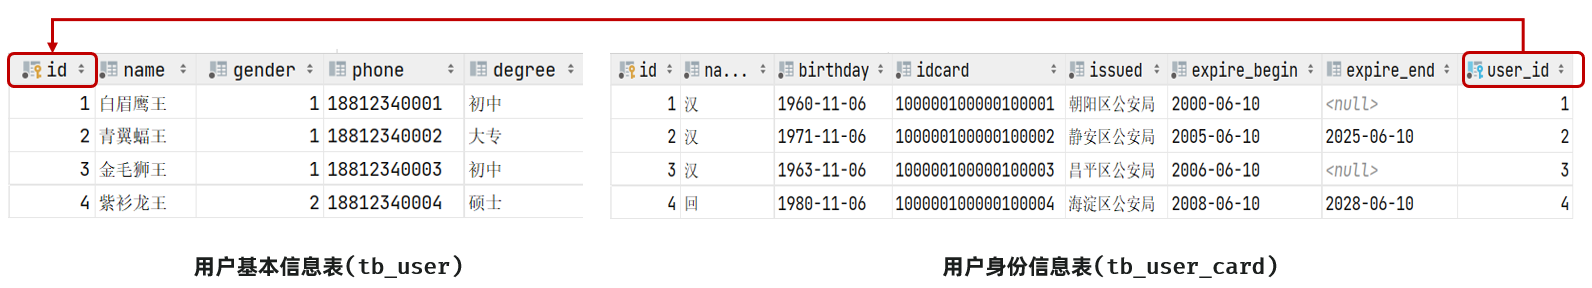

SQL脚本：

````sql
-- 用户基本信息表
create table tb_user(
    id int unsigned  primary key auto_increment comment 'ID',
    name varchar(10) not null comment '姓名',
    gender tinyint unsigned not null comment '性别, 1 男  2 女',
    phone char(11) comment '手机号',
    degree varchar(10) comment '学历'
) comment '用户基本信息表';
-- 测试数据
insert into tb_user values (1,'白眉鹰王',1,'18812340001','初中'),
                        (2,'青翼蝠王',1,'18812340002','大专'),
                        (3,'金毛狮王',1,'18812340003','初中'),
                        (4,'紫衫龙王',2,'18812340004','硕士');

-- 用户身份信息表
create table tb_user_card(
    id int unsigned  primary key auto_increment comment 'ID',
    nationality varchar(10) not null comment '民族',
    birthday date not null comment '生日',
    idcard char(18) not null comment '身份证号',
    issued varchar(20) not null comment '签发机关',
    expire_begin date not null comment '有效期限-开始',
    expire_end date comment '有效期限-结束',
    user_id int unsigned not null unique comment '用户ID',
    constraint fk_user_id foreign key (user_id) references tb_user(id)
) comment '用户身份信息表';
-- 测试数据
insert into tb_user_card values (1,'汉','1960-11-06','100000100000100001','朝阳区公安局','2000-06-10',null,1),
        (2,'汉','1971-11-06','100000100000100002','静安区公安局','2005-06-10','2025-06-10',2),
        (3,'汉','1963-11-06','100000100000100003','昌平区公安局','2006-06-10',null,3),
        (4,'回','1980-11-06','100000100000100004','海淀区公安局','2008-06-10','2028-06-10',4);
````

> <strong>一对一 ：在任意一方加入外键，关联另外一方的主键，并且设置外键为唯一的(UNIQUE)</strong>


### 1.4 多对多

多对多的关系在开发中属于也比较常见的。比如：学生和老师的关系，一个学生可以有多个授课老师，一个授课老师也可以有多个学生。在比如：学生和课程的关系，一个学生可以选修多门课程，一个课程也可以供多个学生选修。

案例：学生与课程的关系

- 关系：一个学生可以选修多门课程，一门课程也可以供多个学生选择
- 实现关系：建立第三张中间表，中间表至少包含两个外键，分别关联两方主键

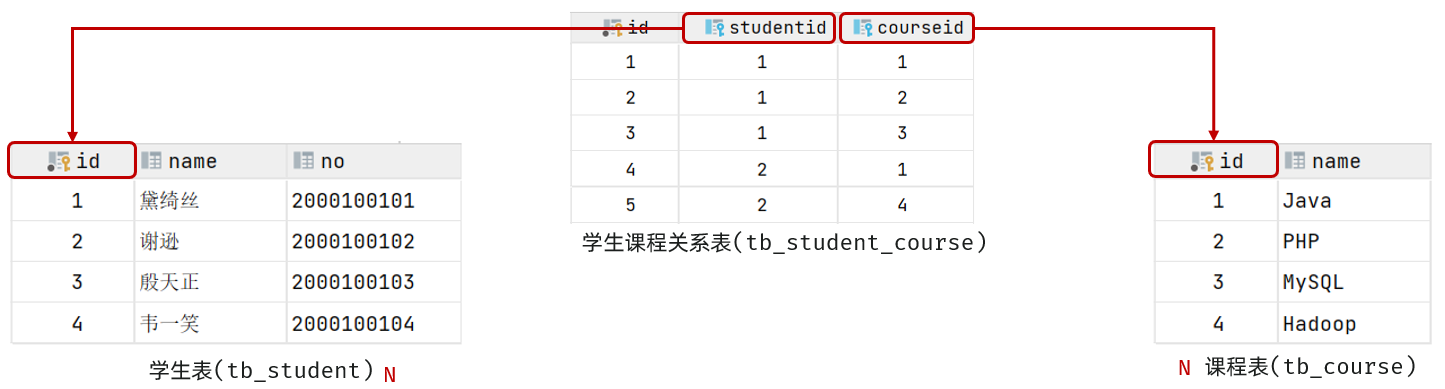

SQL脚本：

````sql
-- 学生表
create table tb_student(
    id int auto_increment primary key comment '主键ID',
    name varchar(10) comment '姓名',
    no varchar(10) comment '学号'
) comment '学生表';
-- 学生表测试数据
insert into tb_student(name, no) values ('黛绮丝', '2000100101'),
                                        ('谢逊', '2000100102'),
                                        ('殷天正', '2000100103'),
                                        ('韦一笑', '2000100104');

-- 课程表
create table tb_course(
   id int auto_increment primary key comment '主键ID',
   name varchar(10) comment '课程名称'
) comment '课程表';
-- 课程表测试数据
insert into tb_course (name) values ('Java'), ('PHP'), ('MySQL') , ('Hadoop');

-- 学生课程表（中间表）
create table tb_student_course(
   id int auto_increment comment '主键' primary key,
   student_id int not null comment '学生ID',
   course_id  int not null comment '课程ID',
   constraint fk_courseid foreign key (course_id) references tb_course (id),
   constraint fk_studentid foreign key (student_id) references tb_student (id)
)comment '学生课程中间表';

-- 学生课程表测试数据
insert into tb_student_course(student_id, course_id) values (1,1),(1,2),(1,3),(2,2),(2,3),(3,4);
````

> <strong>多对多 ：需要建立一张</strong><strong>中间表</strong><strong>，中间表中有两个外键字段，分别关联两方的主键。</strong>


### 1.5 案例

下面通过一个综合案例加深对于多表关系的理解，并掌握多表设计的流程。

<strong>需求</strong>

- 根据参考资料中提供的《Talis智能学习辅助系统》页面原型，设计员工管理模块涉及到的表结构。

<strong>步骤</strong>

- 阅读页面原型及需求文档，分析各个模块涉及到的表结构，及表结构之间的关系。
- 根据页面原型及需求文档，分析各个表结构中具体的字段及约束。

<strong>分析</strong>

涉及到的模块有：

- 部门管理

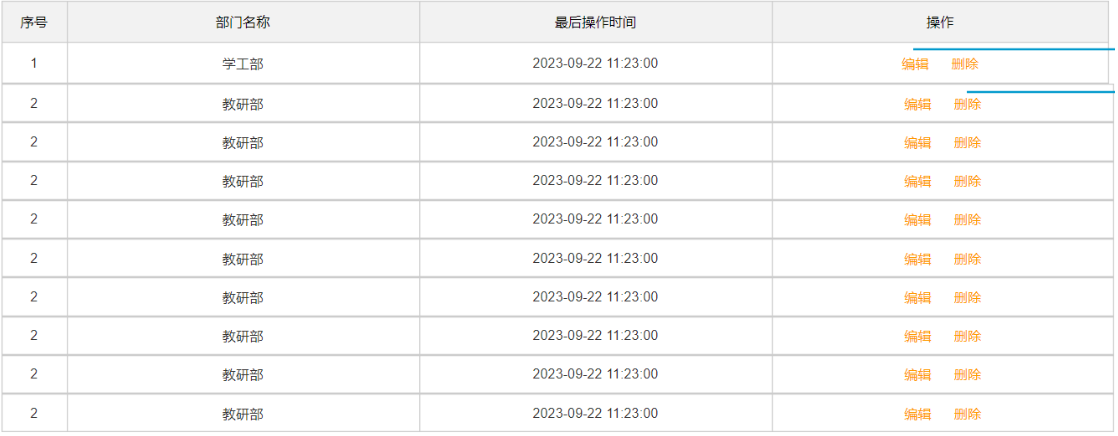

部门管理涉及到一张部门表，这个前面我们都已经设计过了。 无需再进行设计了。

- 员工管理

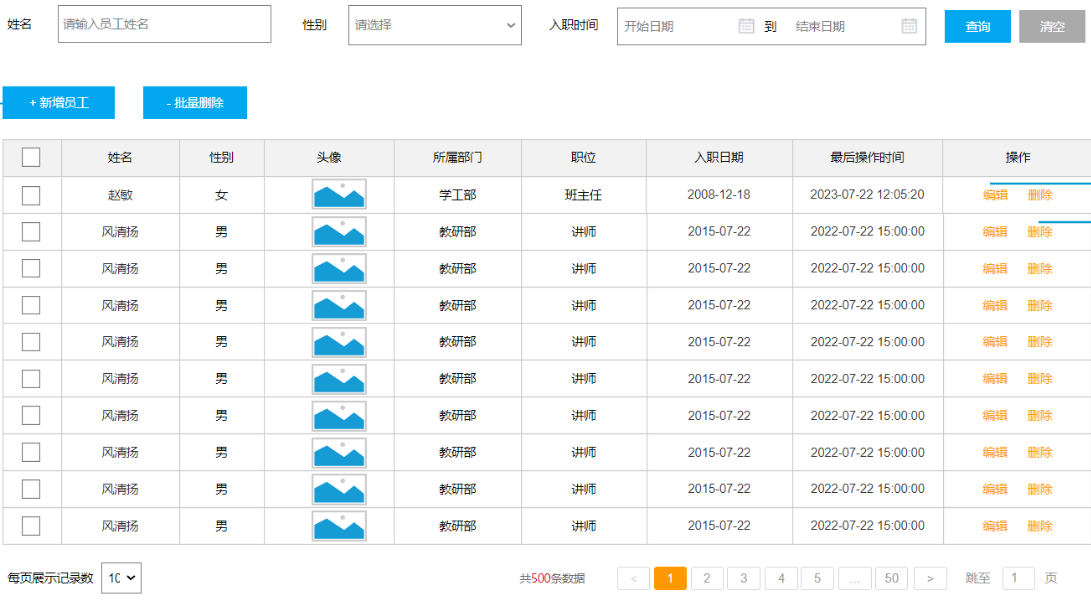

上述在员工列表查询的页面原型，当我们点击 "新增员工" 按钮时，会弹出一个新增员工的表单，表单展示形式如下：

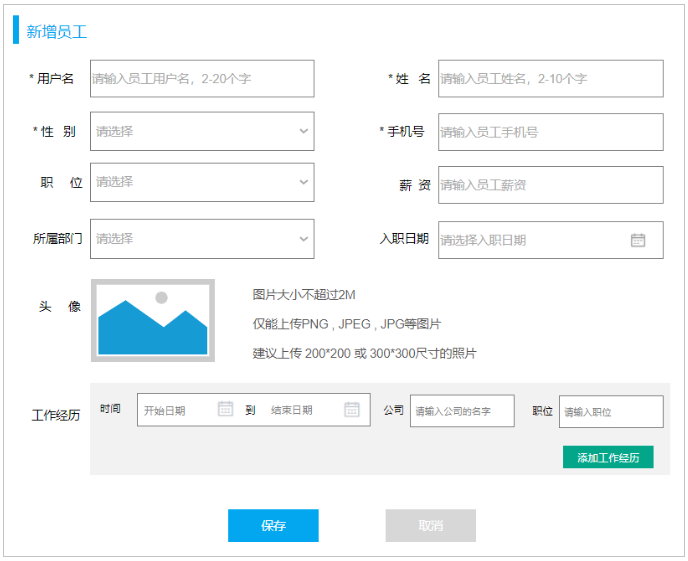

在上述的页面原型中，我们可以看到，每一个员工是归属于某一个部门的，而一个部门下可以有多个员工，所以部门与员工之间的关系是一对多的关系。

从页面员工中，我们可以看到，员工还有工作经历的信息。而每一个员工，是可以添加多个工作经历的。 所以，工作经历我们可以再设计一张表，而员工与员工的工作经历之间的关系，是一对多的关系。

那么，这里总共会涉及三张表，分别是：部门表、员工表、员工工作经历表。

最终，具体的表结构如下：

````sql
-- 部门表
create table dept (
  id int unsigned PRIMARY KEY AUTO_INCREMENT COMMENT 'ID, 主键',
  name varchar(10) NOT NULL UNIQUE COMMENT '部门名称',
  create_time datetime COMMENT '创建时间',
  update_time datetime COMMENT '修改时间'
) COMMENT '部门表';

-- 员工表
create table emp(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) not null unique comment '用户名',
    password varchar(50) default '123456' comment '密码',
    name varchar(10) not null comment '姓名',
    gender tinyint unsigned not null comment '性别, 1:男, 2:女',
    phone char(11) not null unique comment '手机号',
    job tinyint unsigned comment '职位, 1 班主任, 2 讲师 , 3 学工主管, 4 教研主管, 5 咨询师',
    salary int unsigned comment '薪资',
    image varchar(300) comment '头像',
    entry_date date comment '入职日期',
    dept_id int unsigned comment '部门ID',  -- 关联的是dept部门表的ID
    create_time datetime comment '创建时间',
    update_time datetime comment '修改时间'
) comment '员工表';

-- 员工工作经历表
create table emp_expr(
    id int unsigned primary key auto_increment comment 'ID, 主键',
    emp_id  int unsigned null comment '员工ID', -- 关联的是emp员工表的ID
    begin  date null comment '开始时间',
    end date null comment '结束时间',
    company varchar(50) null comment '公司名称',
    job varchar(50) null comment '职位'
) comment '工作经历';
````

注意：在上述的表结构设计中，我们使用的都是逻辑外键。


## 2 多表查询


### 2.1 概述


#### 2.1.1 数据准备

创建数据库，执行如下SQL脚本：

````sql
-- 部门管理
create table dept(
    id int unsigned primary key auto_increment comment 'ID, 主键',
    name varchar(10) not null unique comment '部门名称',
    create_time datetime comment '创建时间',
    update_time datetime comment '修改时间'
) comment '部门表' ;

insert into dept (id, name, create_time, update_time) values
        (1,'学工部',now(),now()),
        (2,'教研部',now(),now()),
        (3,'咨询部',now(),now()),
        (4,'就业部',now(),now()),
        (5,'人事部',now(),now());


-- 员工管理
create table emp(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) not null unique comment '用户名',
    password varchar(32) not null comment '密码',
    name varchar(10) not null comment '姓名',
    gender tinyint unsigned not null comment '性别, 1:男, 2:女',
    phone char(11) not null unique comment '手机号',
    job tinyint unsigned comment '职位, 1:班主任,2:讲师,3:学工主管,4:教研主管,5:咨询师',
    salary int unsigned comment '薪资',
    image varchar(300) comment '头像',
    entry_date date comment '入职日期',
    dept_id int unsigned COMMENT '关联的部门ID',
    create_time datetime comment '创建时间',
    update_time datetime comment '修改时间'
) comment '员工表';


-- 准备测试数据
INSERT INTO `emp` VALUES (1,'shinaian','123456','施耐庵',1,'13309090001',4,15000,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2000-01-01',2,'2023-10-27 16:35:33','2023-10-27 16:35:35'),
                        (2,'songjiang','123456','宋江',1,'13309090002',2,8600,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2015-01-01',2,'2023-10-27 16:35:33','2023-10-27 16:35:37'),
                        (3,'lujunyi','123456','卢俊义',1,'13309090003',2,8900,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2008-05-01',2,'2023-10-27 16:35:33','2023-10-27 16:35:39'),
                        (4,'wuyong','123456','吴用',1,'13309090004',2,9200,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2007-01-01',2,'2023-10-27 16:35:33','2023-10-27 16:35:41'),
                        (5,'gongsunsheng','123456','公孙胜',1,'13309090005',2,9500,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2012-12-05',2,'2023-10-27 16:35:33','2023-10-27 16:35:43'),
                        (6,'huosanniang','123456','扈三娘',2,'13309090006',3,6500,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2013-09-05',1,'2023-10-27 16:35:33','2023-10-27 16:35:45'),
                        (7,'chaijin','123456','柴进',1,'13309090007',1,4700,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2005-08-01',1,'2023-10-27 16:35:33','2023-10-27 16:35:47'),
                        (8,'likui','123456','李逵',1,'13309090008',1,4800,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2014-11-09',1,'2023-10-27 16:35:33','2023-10-27 16:35:49'),
                        (9,'wusong','123456','武松',1,'13309090009',1,4900,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2011-03-11',1,'2023-10-27 16:35:33','2023-10-27 16:35:51'),
                        (10,'lichong','123456','林冲',1,'13309090010',1,5000,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2013-09-05',1,'2023-10-27 16:35:33','2023-10-27 16:35:53'),
                        (11,'huyanzhuo','123456','呼延灼',1,'13309090011',2,9700,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2007-02-01',2,'2023-10-27 16:35:33','2023-10-27 16:35:55'),
                        (12,'xiaoliguang','123456','小李广',1,'13309090012',2,10000,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2008-08-18',2,'2023-10-27 16:35:33','2023-10-27 16:35:57'),
                        (13,'yangzhi','123456','杨志',1,'13309090013',1,5300,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2012-11-01',1,'2023-10-27 16:35:33','2023-10-27 16:35:59'),
                        (14,'shijin','123456','史进',1,'13309090014',2,10600,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2002-08-01',2,'2023-10-27 16:35:33','2023-10-27 16:36:01'),
                        (15,'sunerniang','123456','孙二娘',2,'13309090015',2,10900,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2011-05-01',2,'2023-10-27 16:35:33','2023-10-27 16:36:03'),
                        (16,'luzhishen','123456','鲁智深',1,'13309090016',2,9600,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2010-01-01',2,'2023-10-27 16:35:33','2023-10-27 16:36:05'),
                        (17,'liying','12345678','李应',1,'13309090017',1,5800,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2015-03-21',1,'2023-10-27 16:35:33','2023-10-27 16:36:07'),
                        (18,'shiqian','123456','时迁',1,'13309090018',2,10200,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2015-01-01',2,'2023-10-27 16:35:33','2023-10-27 16:36:09'),
                        (19,'gudasao','123456','顾大嫂',2,'13309090019',2,10500,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2008-01-01',2,'2023-10-27 16:35:33','2023-10-27 16:36:11'),
                        (20,'ruanxiaoer','123456','阮小二',1,'13309090020',2,10800,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2018-01-01',2,'2023-10-27 16:35:33','2023-10-27 16:36:13'),
                        (21,'ruanxiaowu','123456','阮小五',1,'13309090021',5,5200,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2015-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:15'),
                        (22,'ruanxiaoqi','123456','阮小七',1,'13309090022',5,5500,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2016-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:17'),
                        (23,'ruanji','123456','阮籍',1,'13309090023',5,5800,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2012-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:19'),
                        (24,'tongwei','123456','童威',1,'13309090024',5,5000,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2006-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:21'),
                        (25,'tongmeng','123456','童猛',1,'13309090025',5,4800,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2002-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:23'),
                        (26,'yanshun','123456','燕顺',1,'13309090026',5,5400,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2011-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:25'),
                        (27,'lijun','123456','李俊',1,'13309090027',5,6600,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2004-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:27'),
                        (28,'lizhong','123456','李忠',1,'13309090028',5,5000,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2007-01-01',3,'2023-10-27 16:35:33','2023-10-27 16:36:29'),
                        (29,'songqing','123456','宋清',1,'13309090029',NULL,5100,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2020-01-01',NULL,'2023-10-27 16:35:33','2023-10-27 16:36:31'),
                        (30,'liyun','123456','李云',1,'13309090030',NULL,NULL,'https://dawn-itcast.oss-cn-hangzhou.aliyuncs.com/01.png','2020-03-01',NULL,'2023-10-27 16:35:33','2023-10-27 16:36:31');
````


#### 2.1.2 介绍

多表查询：查询时从多张表中获取所需数据

> 单表查询的SQL语句：select  字段列表  from  表名;
> 
> 那么要执行多表查询，只需要使用逗号分隔多张表即可，如： select   字段列表  from  表1, 表2;

查询用户表和部门表中的数据：

````sql
select * from  emp , dept;
````

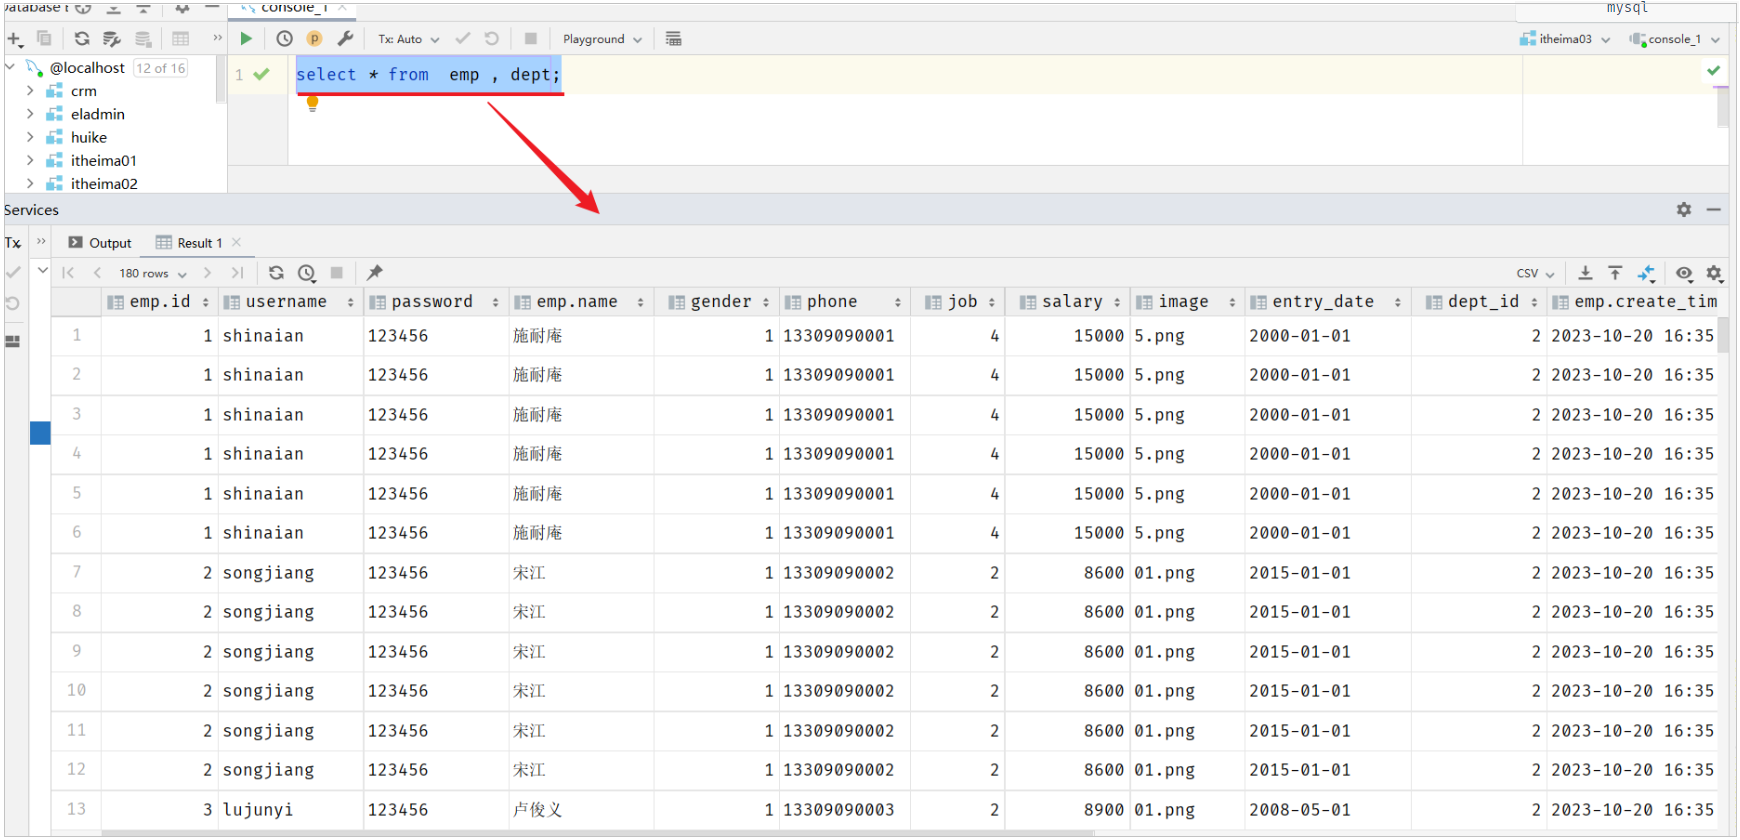

此时，我们看到查询结果中包含了大量的结果集，总共<code>180</code>条记录，而这其实就是员工表所有的记录(30行)与部门表所有记录(6行)的所有组合情况，这种现象称之为<strong>笛卡尔积</strong>。

<strong>笛卡尔积</strong><strong>：</strong>笛卡尔乘积是指在数学中，两个集合(A集合和B集合)的所有组合情况。

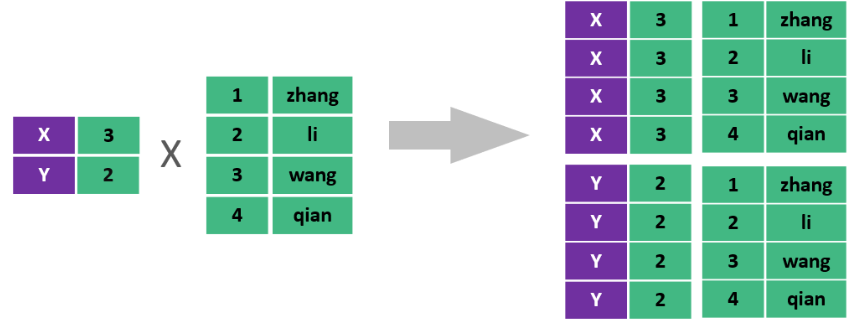

在多表查询时，需要消除无效的笛卡尔积，只保留表关联部分的数据。

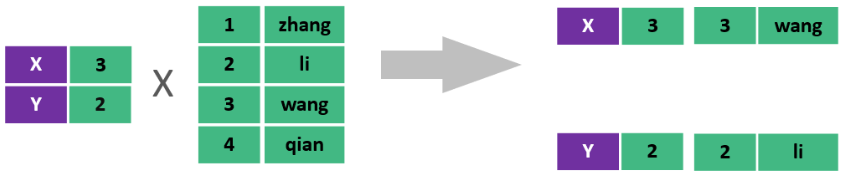

在SQL语句中，如何去除无效的笛卡尔积呢？只需要给多表查询加上连接查询的条件即可。

````sql
select * from emp , dept where emp.dept_id = dept.id ;
````

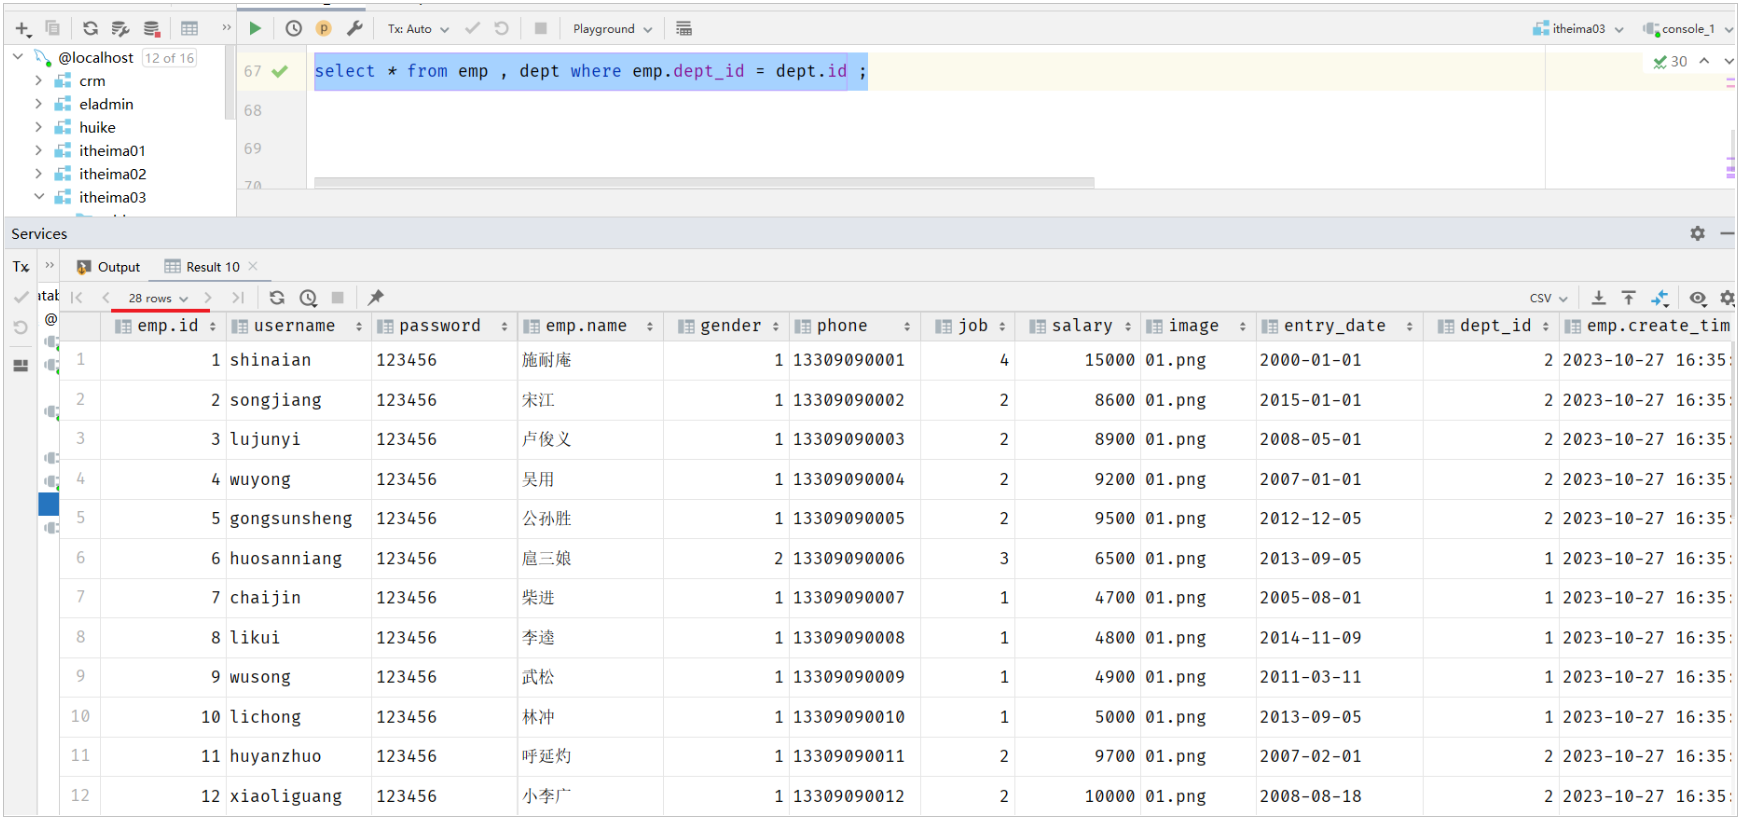

这样，我们就查询出来了所有的员工，及其这个员工所属的部门信息。 而由于id为29、30的员工，没有dept&#95;id字段值，所以在多表查询时，根据连接查询的条件并没有查询到。


#### 2.1.3 分类

多表查询可以分为：

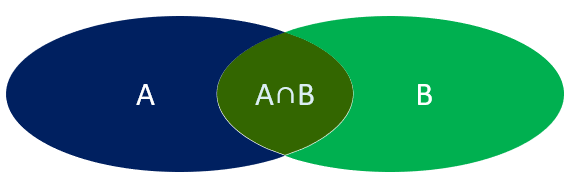

1. 连接查询

    - 内连接：相当于查询A、B交集部分数据
    - 外连接

        - 左外连接：查询左表所有数据(包括两张表交集部分数据)
        - 右外连接：查询右表所有数据(包括两张表交集部分数据)
2. 子查询


### 2.2 内连接

内连接查询：查询两表或多表中交集部分数据。

内连接从语法上可以分为：

- 隐式内连接
- 显式内连接

<strong>隐式内连接语法：</strong>

````sql
select  字段列表   from   表1 , 表2   where  条件 ... ;
````

<strong>显式内连接语法：</strong>

````sql
select  字段列表   from   表1  [ inner ]  join 表2  on  连接条件 ... ;
````

- 案例1：查询所有员工的ID，姓名，及所属的部门名称

    -  隐式内连接实现

    ````sql
    select emp.id, emp.name, dept.name from emp , dept where emp.dept_id = dept.id;
    ````

    - 显式内连接实现

    ````sql
    select emp.id, emp.name, dept.name from emp inner join dept on emp.dept_id = dept.id;
    ````
- 案例2：查询 性别为男, 且工资 高于8000 的员工的ID, 姓名, 及所属的部门名称

    - 隐式内连接实现

    ````sql
    select emp.id, emp.name, dept.name from emp , dept where emp.dept_id = dept.id and emp.gender = 1 and emp.salary > 8000;
    ````

    - 显式内连接实现

    ````sql
    select emp.id, emp.name, dept.name from emp inner join dept on emp.dept_id = dept.id where emp.gender = 1 and emp.salary > 8000;
    ````

    > 在多表联查时，我们指定字段时，需要在字段名前面加上表名，来指定具体是哪一张的字段。 如：emp.dept&#95;id

<strong>给表起别名简化书写：</strong>

````sql
select  字段列表 from 表1 as 别名1 , 表2 as  别名2  where  条件 ... ;

select  字段列表 from 表1 别名1 , 表2  别名2  where  条件 ... ;  -- as 可以省略
````

使用了别名的多表查询：

````sql
select e.id, e.name, d.name from emp as e , dept as d where e.dept_id = d.id and e.gender = 1 and e.salary > 8000;
````

> <strong>注意事项:</strong> 一旦为表起了别名，就不能再使用表名来指定对应的字段了，此时只能够使用别名来指定字段。


### 2.3 外连接

外连接分为两种：左外连接 和 右外连接。

<strong>左外连接语法：</strong>

````sql
select  字段列表   from   表1  left  [ outer ]  join 表2  on  连接条件 ... ;
````

左外连接相当于查询表1(左表)的所有数据，当然也包含表1和表2交集部分的数据。

<strong>右外连接语法：</strong>

````sql
select  字段列表   from   表1  right  [ outer ]  join 表2  on  连接条件 ... ;
````

右外连接相当于查询表2(右表)的所有数据，当然也包含表1和表2交集部分的数据。

案例1：查询员工表 所有 员工的姓名, 和对应的部门名称 (左外连接)

````sql
-- 左外连接：以left join关键字左边的表为主表，查询主表中所有数据，以及和主表匹配的右边表中的数据
select e.name , d.name  from emp as e left join dept as d on e.dept_id = d.id ;
````

案例2：查询部门表 所有 部门的名称, 和对应的员工名称 (右外连接)

````sql
-- 右外连接：以right join关键字右边的表为主表，查询主表中所有数据，以及和主表匹配的左边表中的数据
select e.name , d.name from emp as e right join dept as d on e.dept_id = d.id;
````

案例3：查询工资 高于8000 的 所有员工的姓名, 和对应的部门名称 (左外连接)

````sql
select e.name , d.name  from emp as e left join dept as d on e.dept_id = d.id where e.salary > 8000;
````

> <strong>注意事项：</strong>
> 
> 左外连接和右外连接是可以相互替换的，只需要调整连接查询时SQL语句中表的先后顺序就可以了。而我们在日常开发使用时，更偏向于左外连接。


### 2.4 子查询


#### 2.4.1 介绍

SQL语句中嵌套select语句，称为嵌套查询，又称子查询。

````sql
SELECT  *  FROM   t1   WHERE  column1 =  ( SELECT  column1  FROM  t2 ... );
````

子查询外部的语句可以是insert / update / delete / select 的任何一个，最常见的是 select。

根据子查询结果的不同分为：

1. 标量子查询（子查询结果为单个值 &#91;一行一列&#93;）
2. 列子查询（子查询结果为一列，但可以是多行）
3. 行子查询（子查询结果为一行，但可以是多列）
4. 表子查询（子查询结果为多行多列&#91;相当于子查询结果是一张表&#93;）

子查询可以书写的位置：

1. where之后
2. from之后
3. select之后

> 子查询的要点是，先对需求做拆分，明确具体的步骤，然后再逐条编写SQL语句。 最终将多条SQL语句合并为一条。


#### 2.4.2 标量子查询

子查询返回的结果是单个值(数字、字符串、日期等)，最简单的形式，这种子查询称为<strong>标量子查询</strong>。

常用的操作符： =   &lt;&gt;   &gt;    &gt;=    &lt;   &lt;=   

- 案例1：查询 最早入职 的员工信息

````sql
-- 1. 查询最早的入职时间
select min(entry_date) from emp;  -- 结果: 2000-01-01

-- 2. 查询入职时间 = 最早入职时间的员工信息
select * from emp where entry_date = '2000-01-01';

-- 3. 合并为一条SQL
select * from emp where entry_date = (select min(entry_date) from emp);
````

- 案例2：查询在 阮小五 入职之后入职的员工信息

````sql
-- 1. 查询 "阮小五" 的入职日期
select entry_date from emp where name = '阮小五'; -- 结果: 2015-01-01

-- 2. 根据上述查询到的这个入职日期, 查询在该日期之后入职的员工信息
select * from emp where entry_date > '2015-01-01';

-- 3. 合并SQL为一条SQL
select * from emp where entry_date > (select entry_date from emp where name = '阮小五');
````


#### 2.4.3 列子查询

子查询返回的结果是一列(可以是多行)，这种子查询称为列子查询。

常用的操作符：

| 操作符 | 描述 |
| --- | --- |
| in | 在指定的集合范围之内，多选一 |
| not in | 不在指定的集合范围之内 |

- 案例1：查询 "教研部" 和 "咨询部" 的所有员工信息

````sql
-- 1. 查询 "教研部" 和 "咨询部" 的部门ID
select id from dept where name = '教研部' or name = '咨询部'; -- 结果: 3,2

-- 2. 根据上面查询出来的部门ID, 查询员工信息
select * from emp where dept_id in(3,2);

-- 3. 合并SQL为一条SQL语句
select * from emp where dept_id in (select id from dept where name = '教研部' or name = '咨询部');
````


#### 2.4.4 行子查询

子查询返回的结果是一行(可以是多列)，这种子查询称为行子查询。

常用的操作符：= 、&lt;&gt; 、IN 、NOT IN

- 案例1：查询与 "李忠" 的薪资 及 职位都相同的员工信息

````sql
-- 1. 查询 "李忠" 的薪资和职位
select salary , job from emp where name = '李忠'; -- 结果: 5000, 5

-- 2. 根据上述查询到的薪资和职位 , 查询对应员工的信息
select * from emp where (salary, job) = (5000,5);

-- 3. 将两条SQL合并为一条SQL
select * from emp where (salary, job) = (select salary , job from emp where name = '李忠');
````


#### 2.4.5 表子查询

子查询返回的结果是多行多列，常作为临时表，这种子查询称为<strong>表子查询</strong>。

- 案例：<em>获取每个部门中薪资最高的员工信息</em>

````sql
-- a. 获取每个部门的最高薪资
select dept_id, max(salary) from emp group by dept_id;

-- b. 查询每个部门中薪资最高的员工信息
select * from emp e , (select dept_id, max(salary) max_sal from emp group by dept_id) a
    where e.dept_id = a.dept_id and e.salary = a.max_sal;
````


#### 2.4.6 案例

根据需求，完成多表查询的SQL语句的编写。

- 1. 查询 "教研部" 性别为 男，且在 "2011-05-01" 之后入职的员工信息 。

````sql
select e.* from emp as e , dept as d where e.dept_id = d.id and d.name = '教研部' and e.gender = 1 and e.entry_date > '2011-05-01';
````

- 2. 查询工资 低于公司平均工资的 且 性别为男 的员工信息 。

````sql
select e.* from emp as e , dept as d where e.dept_id = d.id and e.salary < (select avg(salary) from emp) and e.gender = 1;
````

- 3. 查询部门人数超过 10 人的部门名称 。

````sql
select d.name , count(*) from emp as e , dept as d where e.dept_id = d.id group by d.name having count(*) > 10;
````

- 4. 查询在 "2010-05-01" 后入职，且薪资高于 10000 的 "教研部" 员工信息，并根据薪资倒序排序。

````sql
select * from emp e , dept d where e.dept_id = d.id and e.entry_date > '2010-05-01' and e.salary > 10000 and d.name = '教研部' order by e.salary desc;
````

- 5. 查询工资 低于本部门平均工资的员工信息 。【难】

````sql
-- 5.1 查询每个部门的平均工资
select dept_id, avg(salary) avg_sal from emp group by dept_id;

-- 5.2 查询工资 低于本部门平均工资 的员工信息 。
select e.* from emp e , (select dept_id, avg(salary) avg_sal from emp group by dept_id) as a
          where e.dept_id = a.dept_id and e.salary < a.avg_sal;
````


## 3 员工列表查询

那接下来，我们要来完成的是员工列表的查询功能实现。 具体的需求如下：

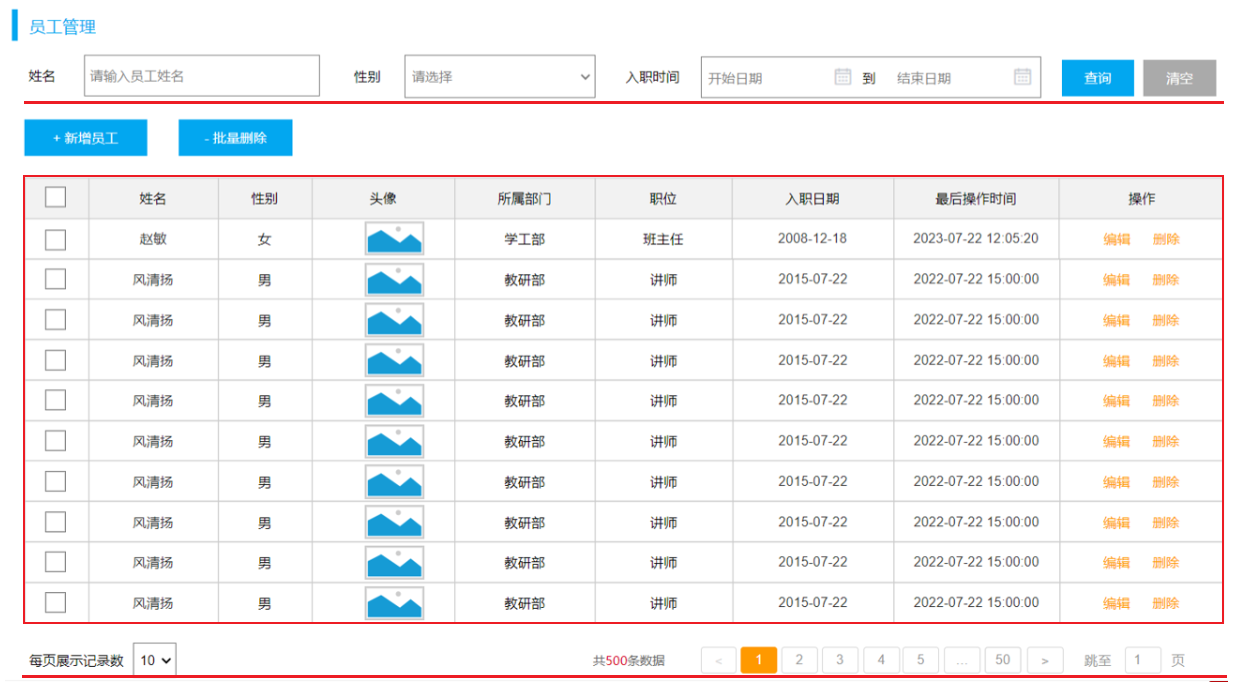

在查询员工列表数据时，既需要查询 员工的基本信息，还需要查询员工所属的部门名称，所以这里呢，会涉及到多表查询的操作。

而且，在查询员工列表数据时，既要考虑搜索栏中的查询条件，还要考虑对查询的结果进行分页处理。

那么接下来，我们在实现这个功能时，将会分为三个部分来逐一实现：

- 准备工作
- 分页查询
- 条件分页查询


### 3.1 准备工作

需求：查询所有员工信息，并查询出部门名称。（涉及到的表：emp、dept）

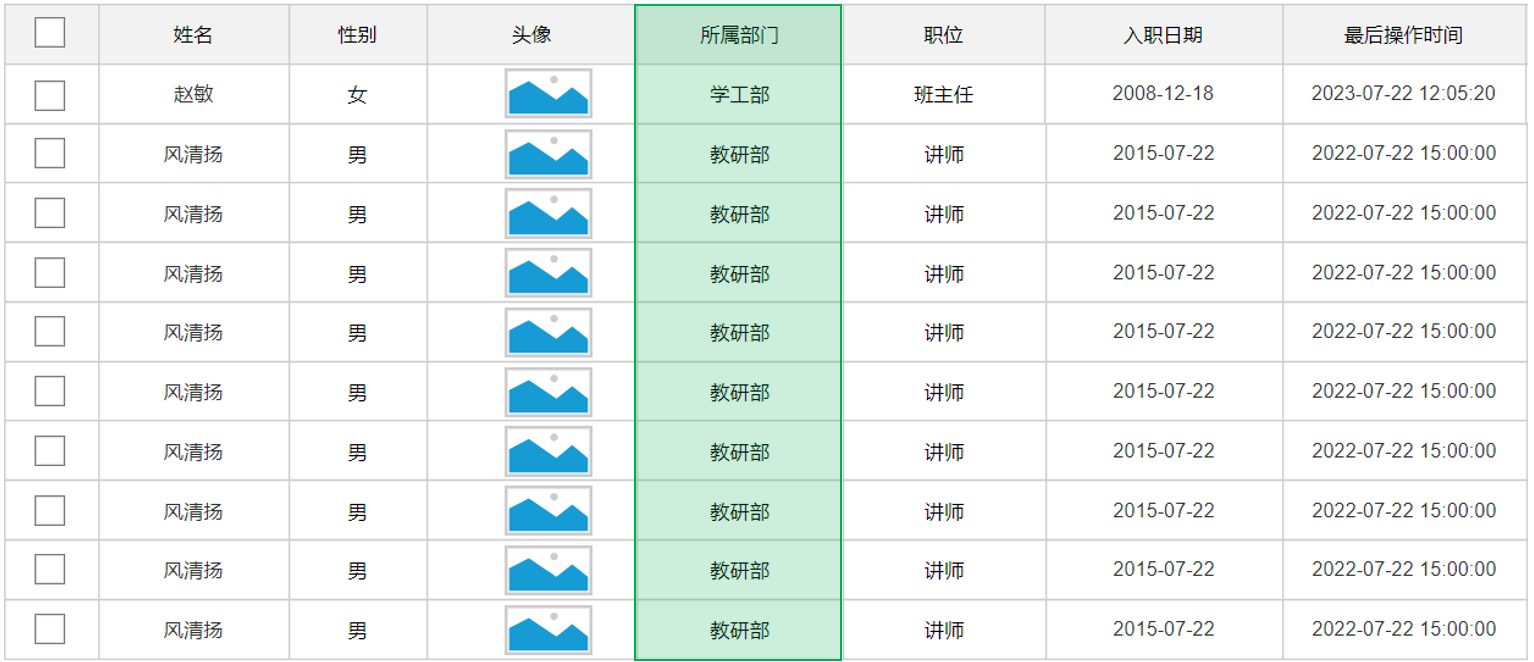


#### 3.1.1 基础代码准备

<strong>1). 创建员工管理相关表结构</strong>

````sql
-- 员工表
create table emp(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) not null unique comment '用户名',
    password varchar(50) default '123456' comment '密码',
    name varchar(10) not null comment '姓名',
    gender tinyint unsigned not null comment '性别, 1:男, 2:女',
    phone char(11) not null unique comment '手机号',
    job tinyint unsigned comment '职位, 1 班主任, 2 讲师 , 3 学工主管, 4 教研主管, 5 咨询师',
    salary int unsigned comment '薪资',
    image varchar(300) comment '头像',
    entry_date date comment '入职日期',
    dept_id int unsigned comment '部门ID',
    create_time datetime comment '创建时间',
    update_time datetime comment '修改时间'
) comment '员工表';


INSERT INTO emp VALUES 
    (1,'shinaian','123456','施耐庵',1,'13309090001',4,15000,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2000-01-01',2,'2023-10-20 16:35:33','2023-11-16 16:11:26'),
    (2,'songjiang','123456','宋江',1,'13309090002',2,8600,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2015-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:37'),
    (3,'lujunyi','123456','卢俊义',1,'13309090003',2,8900,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2008-05-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:39'),
    (4,'wuyong','123456','吴用',1,'13309090004',2,9200,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2007-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:41'),
    (5,'gongsunsheng','123456','公孙胜',1,'13309090005',2,9500,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2012-12-05',2,'2023-10-20 16:35:33','2023-10-20 16:35:43'),
    (6,'huosanniang','123456','扈三娘',2,'13309090006',3,6500,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2013-09-05',1,'2023-10-20 16:35:33','2023-10-20 16:35:45'),
    (7,'chaijin','123456','柴进',1,'13309090007',1,4700,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2005-08-01',1,'2023-10-20 16:35:33','2023-10-20 16:35:47'),
    (8,'likui','123456','李逵',1,'13309090008',1,4800,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2014-11-09',1,'2023-10-20 16:35:33','2023-10-20 16:35:49'),
    (9,'wusong','123456','武松',1,'13309090009',1,4900,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2011-03-11',1,'2023-10-20 16:35:33','2023-10-20 16:35:51'),
    (10,'linchong','123456','林冲',1,'13309090010',1,5000,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2013-09-05',1,'2023-10-20 16:35:33','2023-10-20 16:35:53'),
    (11,'huyanzhuo','123456','呼延灼',1,'13309090011',2,9700,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2007-02-01',2,'2023-10-20 16:35:33','2023-10-20 16:35:55'),
    (12,'xiaoliguang','123456','小李广',1,'13309090012',2,10000,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2008-08-18',2,'2023-10-20 16:35:33','2023-10-20 16:35:57'),
    (13,'yangzhi','123456','杨志',1,'13309090013',1,5300,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2012-11-01',1,'2023-10-20 16:35:33','2023-10-20 16:35:59'),
    (14,'shijin','123456','史进',1,'13309090014',2,10600,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2002-08-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:01'),
    (15,'sunerniang','123456','孙二娘',2,'13309090015',2,10900,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2011-05-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:03'),
    (16,'luzhishen','123456','鲁智深',1,'13309090016',2,9600,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2010-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:05'),
    (17,'liying','12345678','李应',1,'13309090017',1,5800,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2015-03-21',1,'2023-10-20 16:35:33','2023-10-20 16:36:07'),
    (18,'shiqian','123456','时迁',1,'13309090018',2,10200,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2015-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:09'),
    (19,'gudasao','123456','顾大嫂',2,'13309090019',2,10500,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2008-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:11'),
    (20,'ruanxiaoer','123456','阮小二',1,'13309090020',2,10800,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2018-01-01',2,'2023-10-20 16:35:33','2023-10-20 16:36:13'),
    (21,'ruanxiaowu','123456','阮小五',1,'13309090021',5,5200,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2015-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:15'),
    (22,'ruanxiaoqi','123456','阮小七',1,'13309090022',5,5500,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2016-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:17'),
    (23,'ruanji','123456','阮籍',1,'13309090023',5,5800,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2012-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:19'),
    (24,'tongwei','123456','童威',1,'13309090024',5,5000,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2006-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:21'),
    (25,'tongmeng','123456','童猛',1,'13309090025',5,4800,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2002-01-01',3,'2023-10-20 16:35:33','2023-10-20 16:36:23'),
    (26,'yanshun','123456','燕顺',1,'13309090026',5,5400,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2011-01-01',3,'2023-10-20 16:35:33','2023-11-08 22:12:46'),
    (27,'lijun','123456','李俊',1,'13309090027',2,6600,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2004-01-01',2,'2023-10-20 16:35:33','2023-11-16 17:56:59'),
    (28,'lizhong','123456','李忠',1,'13309090028',5,5000,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2007-01-01',3,'2023-10-20 16:35:33','2023-11-17 16:34:22'),
    (30,'liyun','123456','李云',1,'13309090030',NULL,NULL,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2020-03-01',NULL,'2023-10-20 16:35:33','2023-10-20 16:36:31'),
    (36,'linghuchong','123456','令狐冲',1,'18809091212',2,6800,'https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg','2023-10-19',2,'2023-10-20 20:44:54','2023-11-09 09:41:04');
    

-- 员工工作经历信息
create table emp_expr(
    id int unsigned primary key auto_increment comment 'ID, 主键',
    emp_id int unsigned comment '员工ID',
    begin date comment '开始时间',
    end  date comment '结束时间',
    company varchar(50) comment '公司名称',
    job varchar(50) comment '职位'
)comment '工作经历';
````

<strong>2). </strong><strong>准备emp表对应的</strong><strong>实体类</strong><strong>Emp、EmpExpr</strong>

````java
package com.itheima.pojo;

import lombok.Data;

import java.time.LocalDate;
import java.time.LocalDateTime;
import java.util.List;

@Data
public class Emp {
    private Integer id; //ID,主键
    private String username; //用户名
    private String password; //密码
    private String name; //姓名
    private Integer gender; //性别, 1:男, 2:女
    private String phone; //手机号
    private Integer job; //职位, 1:班主任,2:讲师,3:学工主管,4:教研主管,5:咨询师
    private Integer salary; //薪资
    private String image; //头像
    private LocalDate entryDate; //入职日期
    private Integer deptId; //关联的部门ID
    private LocalDateTime createTime; //创建时间
    private LocalDateTime updateTime; //修改时间

    //封装部门名称数
    private String deptName; //部门名称
}
````

````java
package com.itheima.pojo;

import lombok.Data;

import java.time.LocalDate;

/**
 * 工作经历
 */
@Data
public class EmpExpr {
    private Integer id; //ID
    private Integer empId; //员工ID
    private LocalDate begin; //开始时间
    private LocalDate end; //结束时间
    private String company; //公司名称
    private String job; //职位
}
````

<strong>3)</strong><strong>. 准备Emp员工管理的基础结构，包括</strong><strong>Controller、Service、Mapper</strong>

EmpMapper：

````java
package com.itheima.mapper;

import com.itheima.pojo.Emp;
import org.apache.ibatis.annotations.Mapper;
import java.util.List;

@Mapper
public interface EmpMapper {

}
````

EmpService:

````java
package com.itheima.service;

public interface EmpService {
}
````

EmpServiceImpl:

````java
package com.itheima.service.impl;

import com.itheima.mapper.EmpMapper;
import com.itheima.service.EmpService;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;

/**
 * 员工管理
 */
@Service
public class EmpServiceImpl implements EmpService {

    @Autowired
    private EmpMapper empMapper;

}
````

EmpController:

````java
package com.itheima.controller;

import com.itheima.service.EmpService;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.RestController;

/**
 * 员工管理
 */
@Slf4j
@RestController
public class EmpController {

    @Autowired
    private EmpService empService;

}
````


#### 3.1.2 SQL&Mapper接口

**为什么用左连接：**`emp` 为左表时，`dept_id` 为 `NULL` 或对应部门不存在的员工仍会出现在结果中，`deptName` 为 `NULL`。若写 `INNER JOIN`，这类员工会消失。后续把部门条件放进 `WHERE` 时也要留意它会排除 `NULL` 部门行。页面列表应明确排序，否则 `LIMIT` 翻页可能重复或漏项。

那接下来，我们就先考虑一下要查询所有的员工数据，及其关联的部门名称，这个SQL语句该如何实现 ？ 这里，要查询所有的员工，也就意味着，即使员工没有部门，也需要将该员工查询出来 。

所以，这里需要用左外连接实现，具体SQL如下：

<strong>1). 基于AI生成对应的SQL语句</strong>

````sql
-- 查询所有的员工信息，如果员工关联了部门，也要查询出部门名称
select e.*, d.name as dept_name from emp e left join dept d on e.dept_id = d.id;
````

<strong>2). Mapper接口方法定义</strong>

那接下来，我们就定义一个员工管理的mapper接口 <code>EmpMapper</code> 并在其中完成员工信息的查询。 具体代码如下：

````java
@Mapper
public interface EmpMapper {

    /**
     * 查询所有的员工及其对应的部门名称
     */
    @Select("select e.*, d.name as deptName from emp e left join dept d on e.dept_id = d.id")
    public List<Emp> list();

}
````

注意，上述SQL语句中，给 部门名称起了别名 <code>deptName</code> ，是因为在接口文档中，要求部门名称给前端返回的数据中，就必须叫 <code>deptName</code>。 而这里我们需要将查询返回的每一条记录都封装到Emp对象中，那么就必须保证查询返回的字段名与属性名是一一对应的。

此时，我们就需要在Emp中定义一个属性 <code>deptName</code> 用来封装部门名称。 具体如下：

````java
@Data
public class Emp {
    private Integer id; //ID,主键
    private String username; //用户名
    private String password; //密码
    private String name; //姓名
    private Integer gender; //性别, 1:男, 2:女
    private String phone; //手机号
    private Integer job; //职位, 1:班主任,2:讲师,3:学工主管,4:教研主管,5:咨询师
    private Integer salary; //薪资
    private String image; //头像
    private LocalDate entryDate; //入职日期
    private Integer deptId; //关联的部门ID
    private LocalDateTime createTime; //创建时间
    private LocalDateTime updateTime; //修改时间

    //封装部门名称数
    private String deptName; //部门名称
}
````

代码编写完毕后，我们可以编写一个单元测试，对上述的程序进行测试：

````java
@SpringBootTest
class TliasWebManagementApplicationTests {

    @Autowired
    private EmpMapper empMapper;

    @Test
    public void testList(){
        List<Emp> empList = empMapper.list();
        empList.forEach(System.out::println);
    }
}
````

运行单元测试后，我们看到控制台输出的数据：

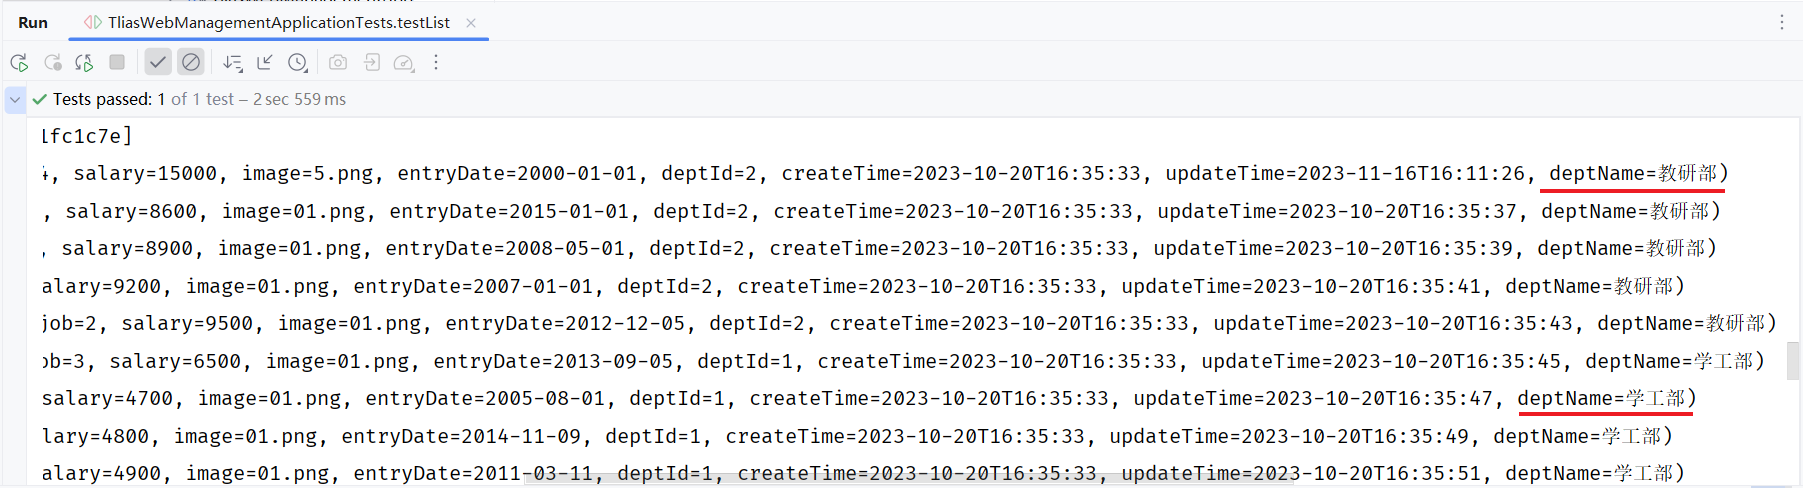

可以看到，员工的信息，员工关联的部门名称都查询出来了。


### 3.2 分页查询


#### 3.2.1 分析

上述我们在Mapper接口中定义了接口方法，完成了查询所有员工及其部门名称的功能，是将数据库中所有的数据查询出来了。 试想如果数据库中的数据有很多(假设有几千几万条)的时候，将数据全部展示出来肯定不现实，那如何解决这个问题呢？

使用分页解决这个问题。每次只展示一页的数据，比如：一页展示10条数据，如果还想看其他的数据，可以通过点击页码进行查询。

而在员工管理的需求中，就要求我们进行分页查询，展示出对应的数据。 具体的页面原型如下：

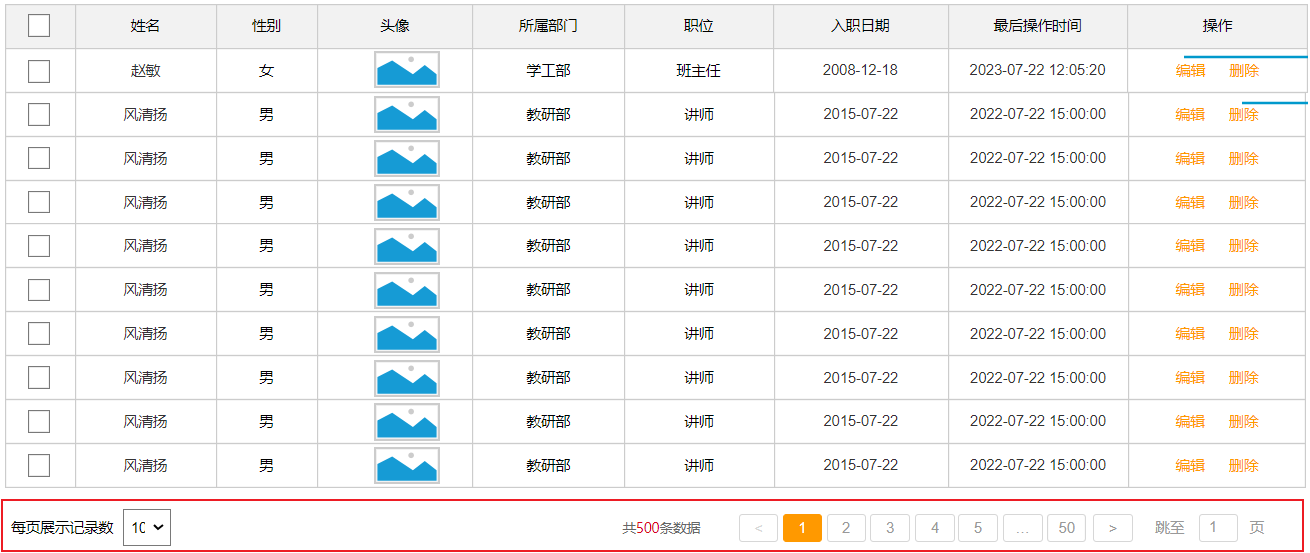

要想从数据库中进行分页查询，我们要使用<code>LIMIT</code>关键字，格式为：limit  开始索引  每页显示的条数。

1). 查询第1页数据的SQL语句是：

````java
select * from emp  limit 0,10;
````

2). 查询第2页数据的SQL语句是：

````java
select * from emp  limit 10,10;
````

3). 查询第3页的数据的SQL语句是：

````java
select * from emp  limit 20,10;
````

观察以上SQL语句，发现： 开始索引一直在改变 ， 每页显示条数是固定的

开始索引的计算公式：   <code>开始索引 = (当前页码 - 1)  &#42;  每页显示条数</code>

我们继续基于页面原型，继续分析，得出以下结论：

1. 前端在请求服务端时，传递的参数

    - 当前页码  page
    - 每页显示条数  pageSize
2. 后端需要响应什么数据给前端

    - 所查询到的数据列表（存储到List 集合中）
    - 总记录数

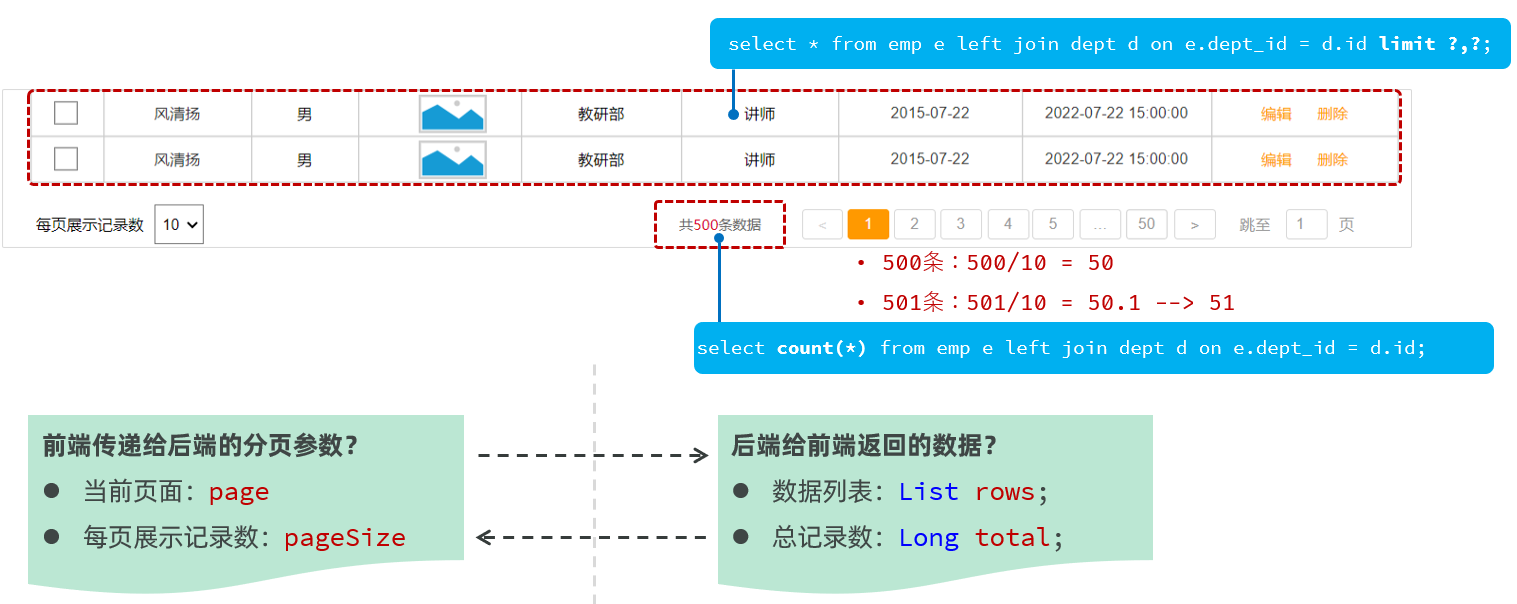

后台给前端返回的数据包含：List集合(数据列表)、total(总记录数)

而这两部分我们通常封装到PageResult对象中，并将该对象转换为json格式的数据响应回给浏览器。

````java
@Data
@NoArgsConstructor
@AllArgsConstructor
public class PageResult {
        private Long total; //总记录数
        private List rows; //当前页数据列表
}
````


#### 3.2.2 接口描述

<strong>1). 基本信息</strong>

> 请求路径：/emps
> 
> 请求方式：GET
> 
> 接口描述：该接口用于员工列表数据的条件分页查询

<strong>2). 请求参数</strong>

| 参数名称 | 是否必须 | 示例 | 备注 |
| --- | --- | --- | --- |
| name | 否 | 张 | 姓名 |
| gender | 否 | 1 | 性别 , 1 男 , 2 女 |
| begin | 否 | 40179 | 范围匹配的开始时间(入职日期) |
| end | 否 | 43831 | 范围匹配的结束时间(入职日期) |
| page | 是 | 1 | 分页查询的页码，如果未指定，默认为1 |
| pageSize | 是 | 10 | 分页查询的每页记录数，如果未指定，默认为10 |

> **表格勘误：**日期样例 `40179`、`43831` 是电子表格内部数值，并非 HTTP 入参格式。`begin/end` 应按下方请求样例传 `yyyy-MM-dd`，如 `2007-09-01`。`page/pageSize` 虽在表中标为必需，但讲义 Controller 配了默认值；实际接口应以实现后的约定为准。

请求数据样例：

````java
/emps?name=张&gender=1&begin=2007-09-01&end=2022-09-01&page=1&pageSize=10
````

<strong>3). 响应数据</strong>

参数格式：application/json

参数说明：

| 名称 | 类型 | 是否必须 | 备注 |
| --- | --- | --- | --- |
| code | number | 必须 | 响应码, 1 成功 , 0 失败 |
| msg | string | 非必须 | 提示信息 |
| data | object | 必须 | 返回的数据 |
|   &#124;- total | number | 必须 | 总记录数 |
|   &#124;- rows | object &#91;&#93; | 必须 | 数据列表 |
|     &#124;- id | number | 非必须 | id |
|     &#124;- username | string | 非必须 | 用户名 |
|     &#124;- name | string | 非必须 | 姓名 |
|     &#124;- password | string | 非必须 | 密码 |
|     &#124;- gender | number | 非必须 | 性别 , 1 男 ; 2 女 |
|     &#124;- image | string | 非必须 | 图像 |
|     &#124;- job | number | 非必须 | 职位, 说明: 1 班主任,2 讲师, 3 学工主管, 4 教研主管, 5 咨询师 |
|     &#124;- salary | number | 非必须 | 薪资 |
|     &#124;- entryDate | string | 非必须 | 入职日期 |
|     &#124;- deptId | number | 非必须 | 部门id |
|     &#124;- deptName | string | 非必须 | 部门名称 |
|     &#124;- createTime | string | 非必须 | 创建时间 |
|     &#124;- updateTime | string | 非必须 | 更新时间 |

> **安全勘误：**表格把 `password` 写进 `rows`，真实列表接口不得返回密码或密码哈希。`phone`、`salary` 等字段也要按权限和页面需求决定是否展示。

响应数据样例：

````json
{
  "code": 1,
  "msg": "success",
  "data": {
    "total": 2,
    "rows": [
       {
        "id": 1,
        "username": "jinyong",
        "password": "123456",
        "name": "金庸",
        "gender": 1,
        "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2022-09-02-00-27-53B.jpg",
        "job": 2,
        "salary": 8000,
        "entryDate": "2015-01-01",
        "deptId": 2,
        "deptName": "教研部",
        "createTime": "2022-09-01T23:06:30",
        "updateTime": "2022-09-02T00:29:04"
      },
      {
        "id": 2,
        "username": "zhangwuji",
        "password": "123456",
        "name": "张无忌",
        "gender": 1,
        "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2022-09-02-00-27-53B.jpg",
        "job": 2,
        "salary": 6000,
        "entryDate": "2015-01-01",
        "deptId": 2,
        "deptName": "教研部",
        "createTime": "2022-09-01T23:06:30",
        "updateTime": "2022-09-02T00:29:04"
      }
    ]
  }
}
````

> **接口安全勘误：**讲义的响应样例和字段表包含 `password`，这是教学数据展示，不应作为实际接口契约。员工列表只返回页面需要的字段；敏感字段应从查询投影和响应 DTO 中排除，而不只是前端隐藏。真实密码还应存储哈希，不能使用示例明文。

目前我们只考虑分页查询，先不考虑查询条件，而上述的接口文档中，与分页查询相关的参数就两个，一个是page，一个是pageSize。


#### 3.2.3 原始方式


##### 3.2.3.1 代码实现

通过查看接口文档：员工列表查询

> 请求路径：/emps
> 
> 请求方式：GET
> 
> 请求参数：跟随在请求路径后的参数字符串。  例：/emps?page=1&amp;pageSize=10
> 
> 响应数据：json格式

<strong>1). </strong><strong>EmpController</strong>

````java
@Slf4j
@RequestMapping("/emps")
@RestController
public class EmpController {
        
    @Autowired
    private EmpService empService;
        
    @GetMapping
    public Result page(@RequestParam(defaultValue = "1") Integer page ,
                       @RequestParam(defaultValue = "10") Integer pageSize){
        log.info("查询员工信息, page={}, pageSize={}", page, pageSize);
        PageResult pageResult = empService.page(page, pageSize);
        return Result.success(pageBean);
    }
        
}
````

> **勘误：**示例先定义 `PageResult pageResult`，返回时却写了 `Result.success(pageBean)`，`pageBean` 未定义，无法编译。应返回 `Result.success(pageResult)`。分页入参还应校验 `page >= 1`、`pageSize` 在合理上限内，计算偏移量时防止溢出。

> @RequestParam(defaultValue="默认值")   //设置请求参数默认值

<strong>2). EmpService</strong>

````java
public interface EmpService {
    /**
     * 分页查询
     * @param page 页码
     * @param pageSize 每页记录数
     */
    PageResult page(Integer page, Integer pageSize);
}
````

<strong>3). EmpServiceImpl</strong>

````java
@Service
public class EmpServiceImpl implements EmpService {

    @Autowired
    private EmpMapper empMapper;

    @Override
    public PageResult page(Integer page, Integer pageSize) {
        //1. 获取总记录数
        Long total = empMapper.count();

        //2. 获取结果列表
        Integer start = (page - 1) * pageSize;
        List<Emp> empList = empMapper.list(start, pageSize);

        //3. 封装结果
        return new PageResult(total, empList);
    }
}
````

<strong>4). EmpMapper</strong>

````java
@Mapper
public interface EmpMapper {

    /**
     * 查询总记录数
     */
    @Select("select count(*) from emp e left join dept d on e.dept_id = d.id ")
    public Long count();
    
    /**
     * 查询所有的员工及其对应的部门名称
     */
    @Select("select e.*, d.name deptName from emp as e left join dept as d on e.dept_id = d.id limit #{start}, #{pageSize}")
    public List<Emp> list(Integer start , Integer pageSize);

}
````


##### 3.2.3.2 功能测试

功能开发完成后，重新启动项目，使用Apifox，发起GET请求：

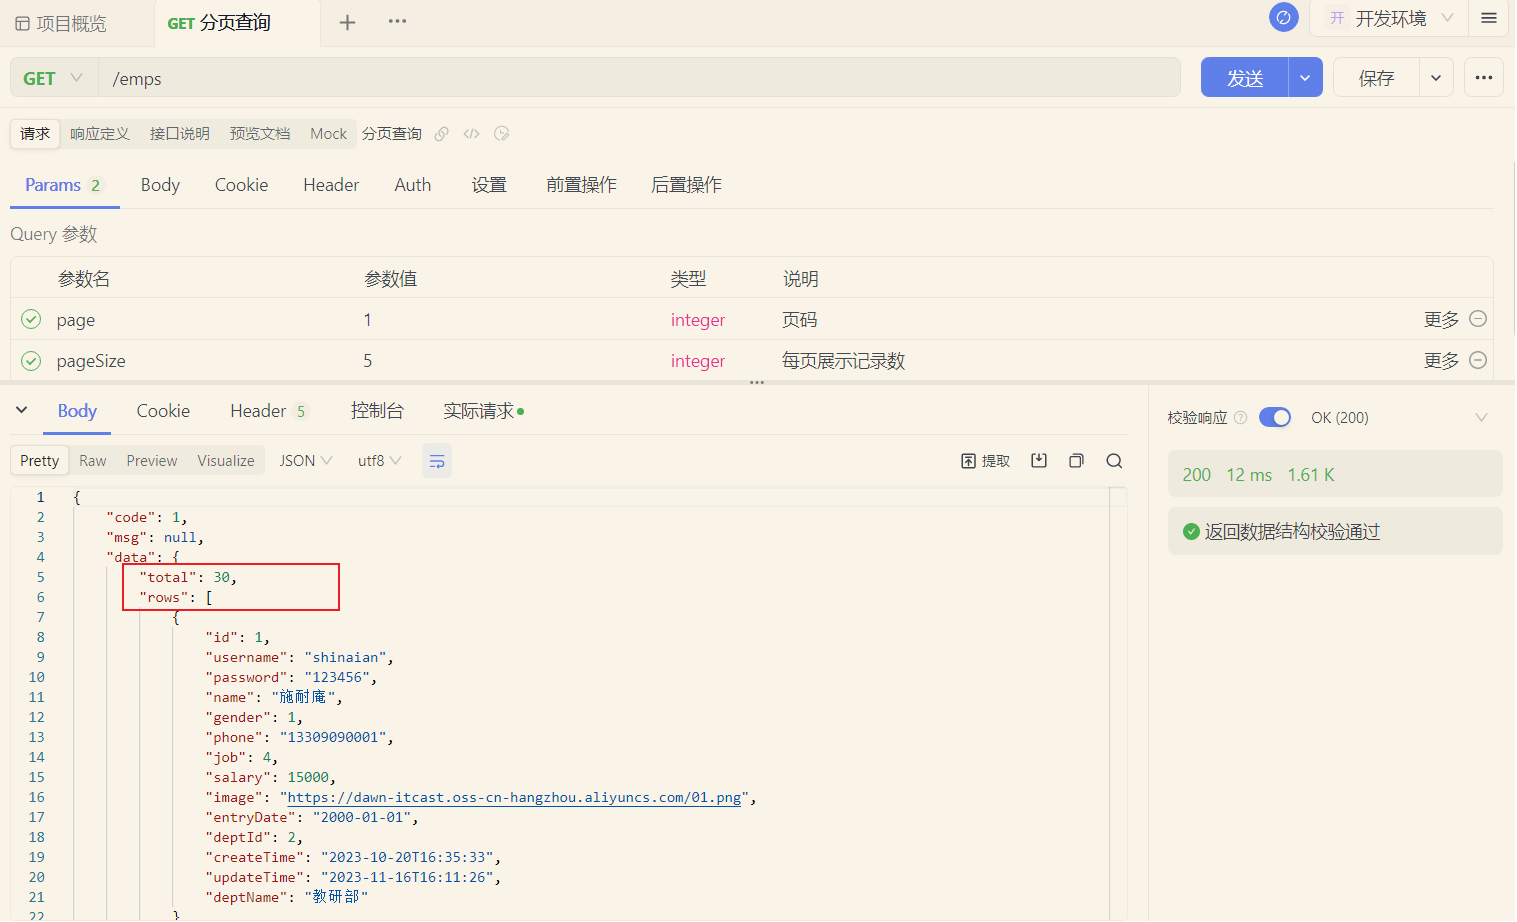


##### 3.2.3.3 前后端联调

打开浏览器，测试后端功能接口：

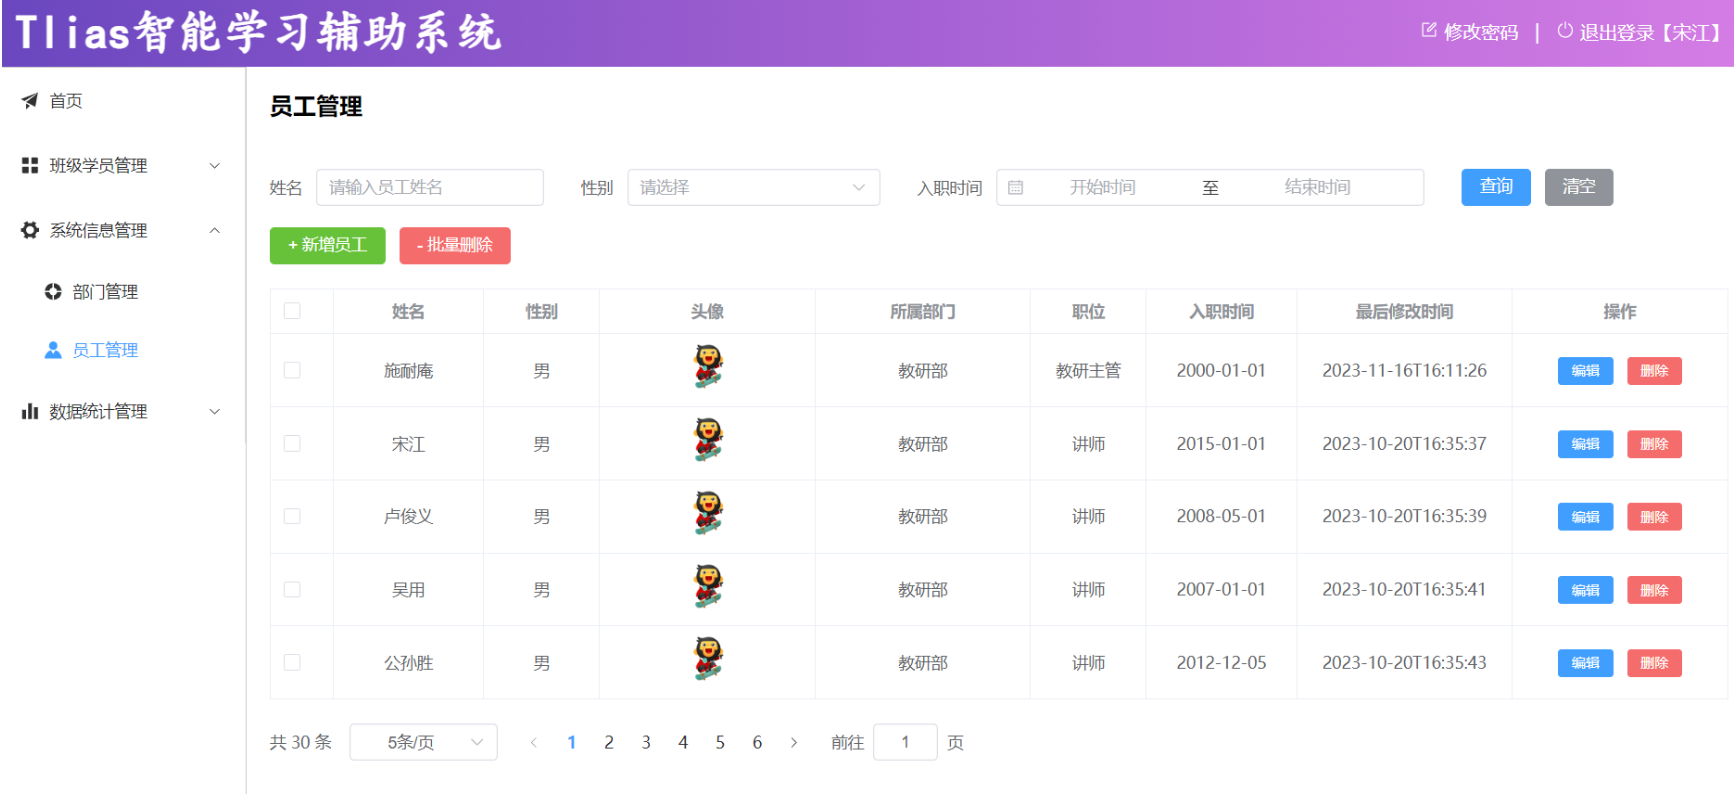

点击下面的页码，可以正常的查询出对应的数据 。


#### 3.2.4 PageHelper分页插件


##### 3.2.4.1 介绍

前面我们已经完了基础的分页查询，大家会发现：分页查询功能编写起来比较繁琐。 而分页查询的功能是非常常见的，我们查询员工信息需要分页查询，将来在做其他项目时，查询用户信息、订单信息、商品信息等等都是需要进行分页查询的。

而分页查询的思路、步骤是比较固定的。 在Mapper接口中定义两个方法执行两条不同的SQL语句：

1. 查询总记录数
2. 指定页码的数据列表

在Service当中，调用Mapper接口的两个方法，分别获取：总记录数、查询结果列表，然后在将获取的数据结果封装到PageBean对象中。

大家思考下：在未来开发其他项目，只要涉及到分页查询功能(例：订单、用户、支付、商品)，都必须按照以上操作完成功能开发

结论：原始方式的分页查询，存在着"步骤固定"、"代码频繁"的问题

解决方案：可以使用一些现成的分页插件完成。对于Mybatis来讲现在最主流的就是PageHelper。

<strong>PageHelper是第三方提供的Mybatis框架中的一款功能强大、方便易用的分页插件，支持任何形式的单标、多表的分页查询。</strong>

官网：https://pagehelper.github.io/

那接下来，我们可以对比一下，使用PageHelper分页插件进行分页 与 原始方式进行分页代码实现的上的差别。

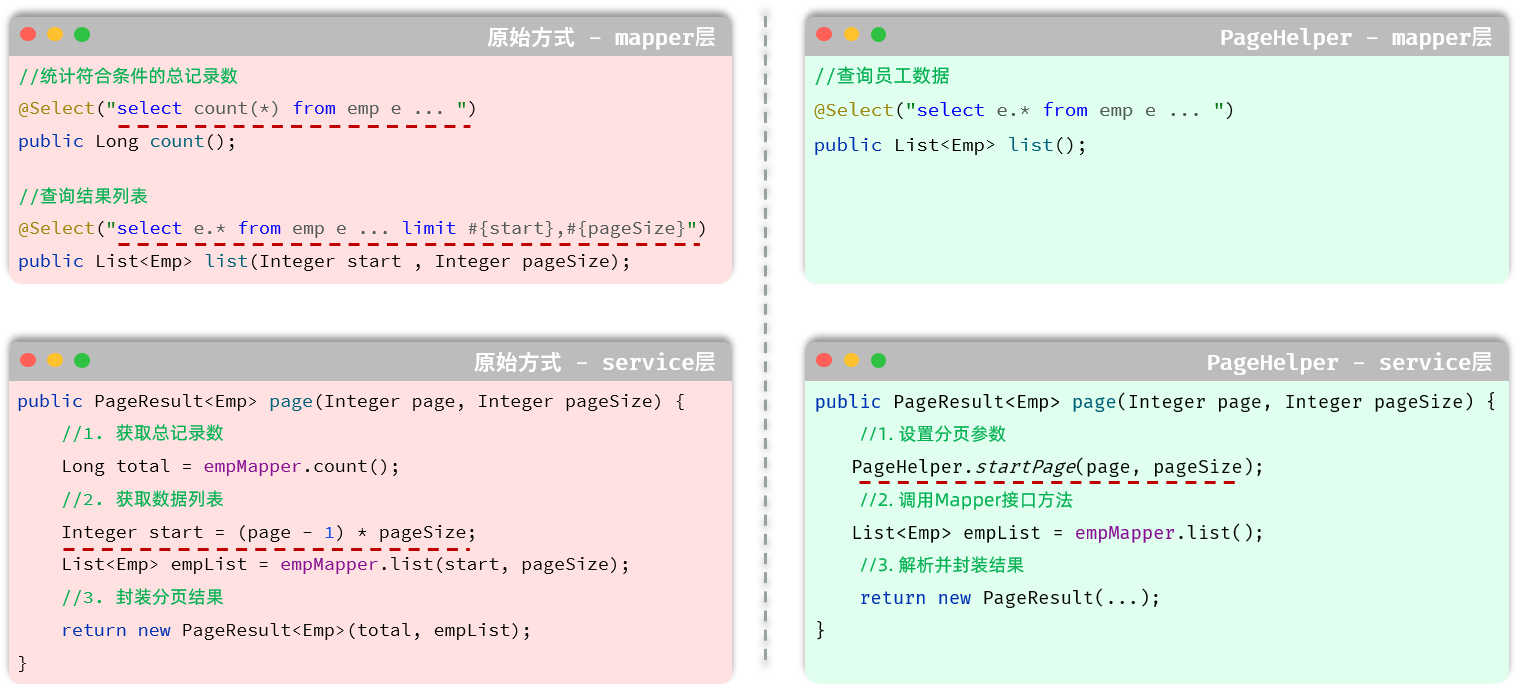

- Mapper接口层：

    - 原始的分页查询功能中，我们需要在Mapper接口中定义两条SQL语句。   
    - PageHelper实现分页查询之后，只需要编写一条SQL语句，而且不需要考虑分页操作，就是一条正常的查询语句。
- Service层：

    - 需要根据页码、每页展示记录数，手动的计算起始索引。
    - 无需手动计算起始索引，直接告诉PageHelper需要查询那一页的数据，每页展示多少条记录即可。


##### 3.2.4.2 代码实现

当使用了PageHelper分页插件进行分页，就无需再Mapper中进行手动分页了。 在Mapper中我们只需要进行正常的列表查询即可。在Service层中，调用Mapper的方法之前设置分页参数，在调用Mapper方法执行查询之后，解析分页结果，并将结果封装到PageResult对象中返回。

1). 在pom.xml引入依赖

````xml
<!--分页插件PageHelper-->
<dependency>
    <groupId>com.github.pagehelper</groupId>
    <artifactId>pagehelper-spring-boot-starter</artifactId>
    <version>1.4.7</version>
</dependency>
````

2). EmpMapper

````java
/**
 * 查询所有的员工及其对应的部门名称
 */
@Select("select e.*, d.name deptName from emp as e left join dept as d on e.dept_id = d.id")
public List<Emp> list();
````

3). EmpServiceImpl

````java
@Override
public PageResult page(Integer page, Integer pageSize) {
    //1. 设置分页参数
    PageHelper.startPage(page,pageSize);

    //2. 执行查询
    List<Emp> empList = empMapper.list();
    Page<Emp> p = (Page<Emp>) empList;

    //3. 封装结果
    return new PageResult(p.getTotal(), p.getResult());
}
````


##### 3.2.4.3 功能测试

功能开发完成后，我们重启项目工程，打开Apifox，发起GET请求，访问 ：http://localhost:8080/emps?page=1&amp;pageSize=5

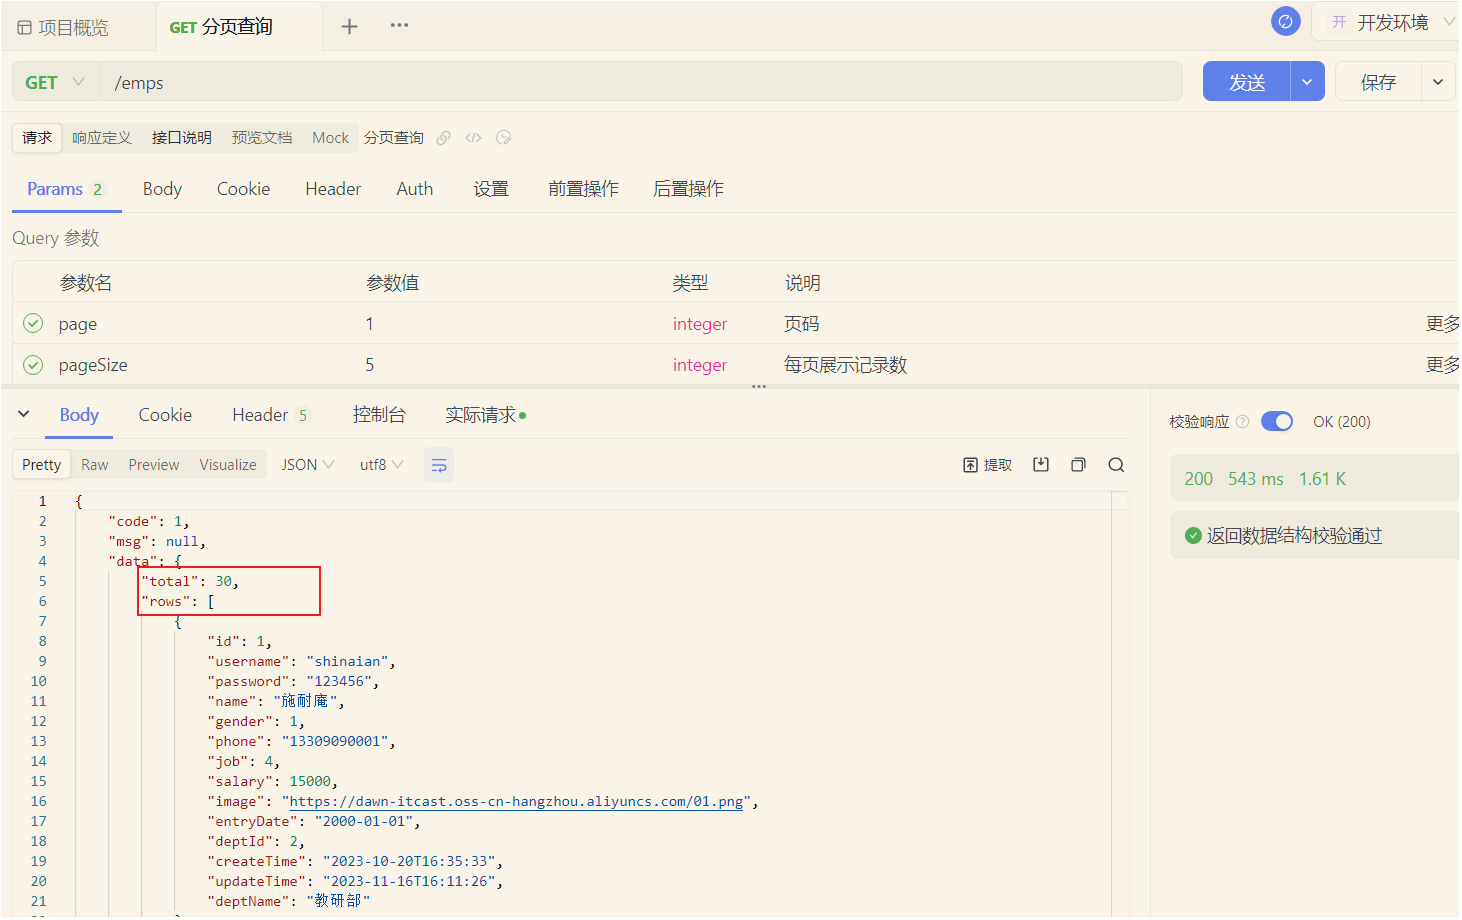

我们可以看到数据可以正常查询返回，是可以正常实现分页查询的。


##### 3.2.4.4 实现机制

> **PageHelper 使用边界：**`startPage` 作用于当前线程下一条 MyBatis 查询，必须紧贴目标 Mapper 调用。不要在两者之间插入其他查询，也不要把已加 `LIMIT` 的 SQL 再交给插件分页。复杂联表、`GROUP BY` 或聚合 SQL 的自动 `count` 改写可能不符合预期，应查看实际 SQL 并验证总数。讲义的 starter 版本应和当前 Spring Boot/MyBatis 版本逐一核对。

我们打开Idea的控制台，可以看到在进行分页查询时，输出的SQL语句。

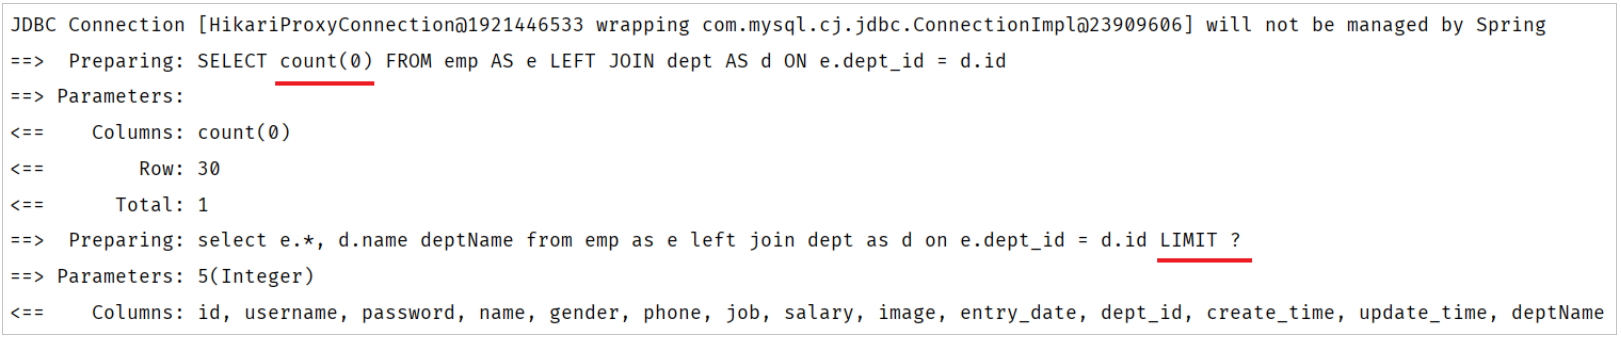

我们看到执行了两条SQL语句，而这两条SQL语句，其实是从我们在Mapper接口中定义的SQL演变而来的。

- 第一条SQL语句，用来查询总记录数。 

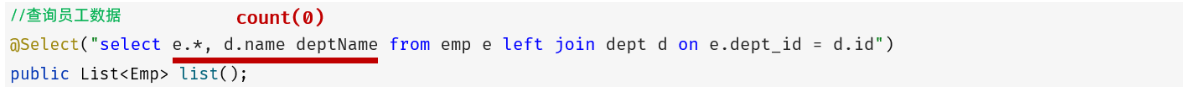

其实就是将我们编写的SQL语句进行的改造增强，将查询返回的字段列表替换成了 <code>count(0)</code> 来统计总记录数。

- 第二条SQL语句，用来进行分页查询，查询指定页码对应 的数据列表。

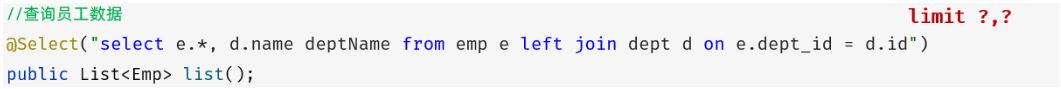

其实就是将我们编写的SQL语句进行的改造增强，在SQL语句之后拼接上了limit进行分页查询，而由于测试时查询的是第一页，起始索引是0，所以简写为limit ？。

而PageHelper在进行分页查询时，会执行上述两条SQL语句，并将查询到的总记录数，与数据列表封装到了 <code>Page&lt;Emp&gt;</code> 对象中，我们再获取查询结果时，只需要调用Page对象的方法就可以获取。

> <strong>注意：</strong>
> 
> - PageHelper实现分页查询时，SQL语句的结尾一定一定一定不要加分号(;).。
> - PageHelper只会对紧跟在其后的第一条SQL语句进行分页处理。


### 3.3 条件分页查询

完了分页查询后，下面我们需要在分页查询的基础上，添加条件。


#### 3.3.1 需求

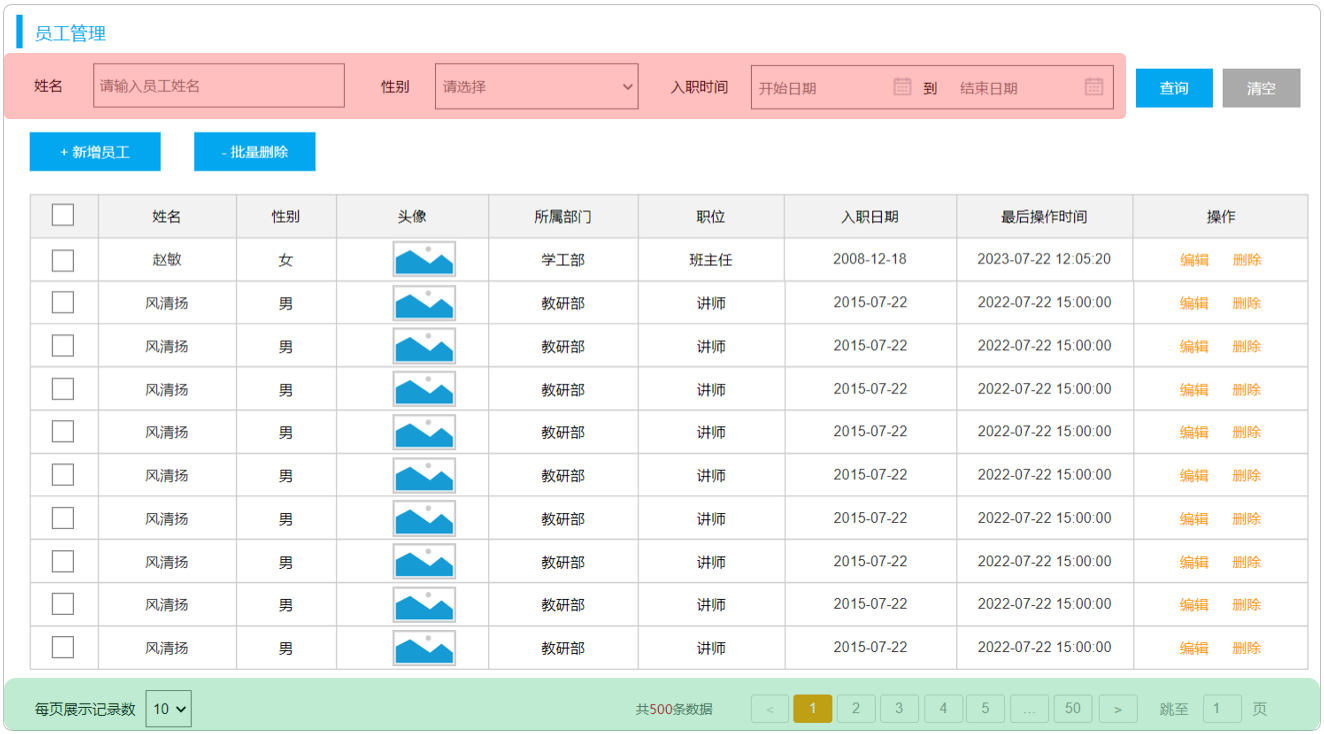

通过员工管理的页面原型我们可以看到，员工列表页面的查询，不仅仅需要考虑分页，还需要考虑查询条件。 分页查询我们已经实现了，接下来，我们需要考虑在分页查询的基础上，再加上查询条件。

我们看到页面原型及需求中描述，搜索栏的搜索条件有三个，分别是：

- 姓名：模糊匹配
- 性别：精确匹配
- 入职日期：范围匹配


#### 3.3.2 接口描述

参照接口文档中的 <code>员工管理</code> -&gt; <code>员工列表查询</code>


#### 3.3.3 思路分析

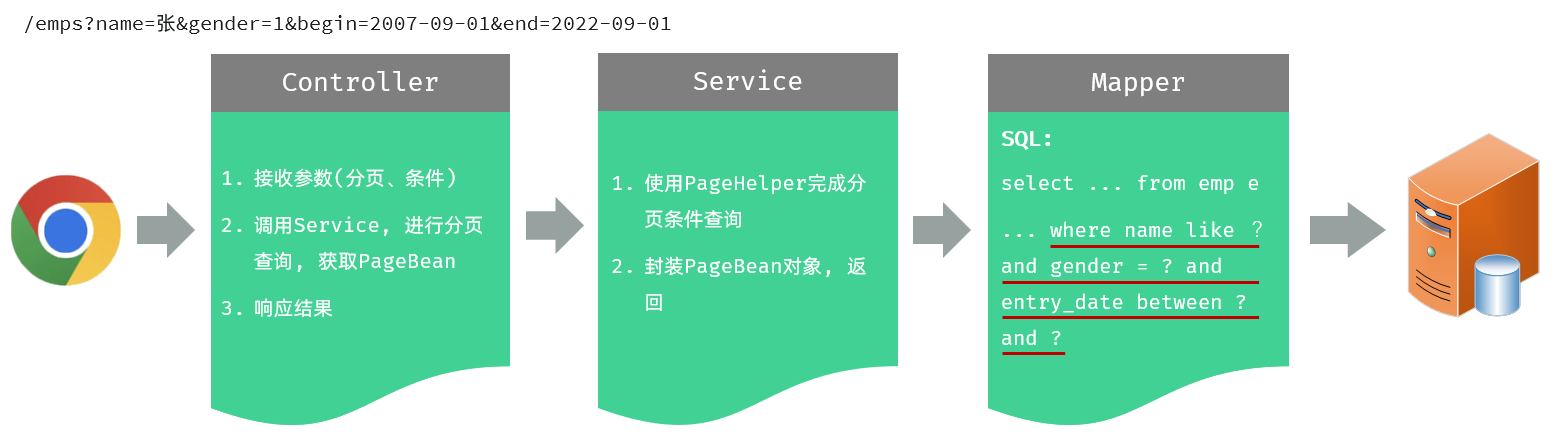


#### 3.3.4 功能开发

通过查看接口文档：员工列表查询

请求路径：/emps

请求方式：GET

请求参数：

| 参数名称 | 是否必须 | 示例 | 备注 |
| --- | --- | --- | --- |
| name | 否 | 张 | 姓名 |
| gender | 否 | 1 | 性别 , 1 男 , 2 女 |
| begin | 否 | 40179 | 范围匹配的开始时间(入职日期) |
| end | 否 | 43831 | 范围匹配的结束时间(入职日期) |
| page | 是 | 1 | 分页查询的页码，如果未指定，默认为1 |
| pageSize | 是 | 10 | 分页查询的每页记录数，如果未指定，默认为10 |

> **表格勘误：**`begin/end` 的 `40179`、`43831` 是表格日期序列值；GET 请求使用 `yyyy-MM-dd` 文本。`page/pageSize` 有默认值时可以省略，同时要限制最大页大小。

在原有分页查询的代码基础上进行改造。

<strong>1). 在EmpController方法中通过多个方法形参，依次接收这几个参数</strong>

````java
@Slf4j
@RestController
@RequestMapping("/emps")
public class EmpController {

    @Autowired
    private EmpService empService;

    @GetMapping
    public Result page(@RequestParam(defaultValue = "1") Integer page,
                       @RequestParam(defaultValue = "10") Integer pageSize,
                       String name, Integer gender,
                       @DateTimeFormat(pattern = "yyyy-MM-dd") LocalDate begin,
                       @DateTimeFormat(pattern = "yyyy-MM-dd") LocalDate end) {
        log.info("查询请求参数： {}, {}, {}, {}, {}, {}", page, pageSize, name, gender, begin, end);
        PageResult pageResult = empService.page(page, pageSize);
        return Result.success(pageResult);
    }
}
````

> **勘误：**这一版 Controller 接收了 `name/gender/begin/end`，却只调用 `empService.page(page, pageSize)`；与下一段六参数 `EmpService.page(...)` 不一致，也不会按条件筛选。这里应把六个参数全部传入，或直接采用后文的 `EmpQueryParam` 版本。讲义按演进过程展示片段，同名类不能全部复制进项目。

<strong>2). 修改EmpService及EmpServiceImpl中的代码逻辑</strong>

EmpService：

````java
public interface EmpService {
    /**
     * 分页查询
     */
    PageResult page(Integer page, Integer pageSize, String name, Integer gender, LocalDate begin, LocalDate end);
}
````

EmpServiceImpl:

````java
/**
 * 员工管理
 */
@Service
public class EmpServiceImpl implements EmpService {

    @Autowired
    private EmpMapper empMapper;

    @Override
    public PageResult page(Integer page, Integer pageSize, String name, Integer gender, LocalDate begin, LocalDate end) {
        //1. 设置PageHelper分页参数
        PageHelper.startPage(page, pageSize);
        //2. 执行查询
        List<Emp> empList = empMapper.list(name, gender, begin, end);
        //3. 封装分页结果
        Page<Emp> p = (Page<Emp>) empList;
        return new PageResult(p.getTotal(), p.getResult());
    }
}
````

<strong>3). 调整EmpMapper接口方法</strong>

````java
@Mapper
public interface EmpMapper {
    
    /**
     * 查询所有的员工及其对应的部门名称
     */
    public List<Emp> list(String name, Integer gender, LocalDate begin, LocalDate end);
    
}
````

由于SQL语句比较复杂，建议将SQL语句配置在XML映射文件中。

> **参数绑定：**当 Mapper 有多个独立形参时，建议用 `@Param("name")` 等显式命名；改为单个 `EmpQueryParam` 对象后，XML 可直接用属性名。XML 文件放在 `src/main/resources` 下，并确保 `namespace` 与 Mapper 全限定名、`select id` 与方法名一致。

<strong>4). 新增Mapper映射文件</strong><strong><code>EmpMapper.xml</code></strong>

````xml
<!--定义Mapper映射文件的约束和基本结构-->
<!DOCTYPE mapper
        PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.EmpMapper">
    <select id="list" resultType="com.itheima.pojo.Emp">
        select e.*, d.name deptName from emp as e left join dept as d on e.dept_id = d.id
        where e.name like concat('%',#{name},'%')
          and e.gender = #{gender}
          and e.entry_date between #{begin} and #{end}
    </select>
</mapper>
````

功能测试：

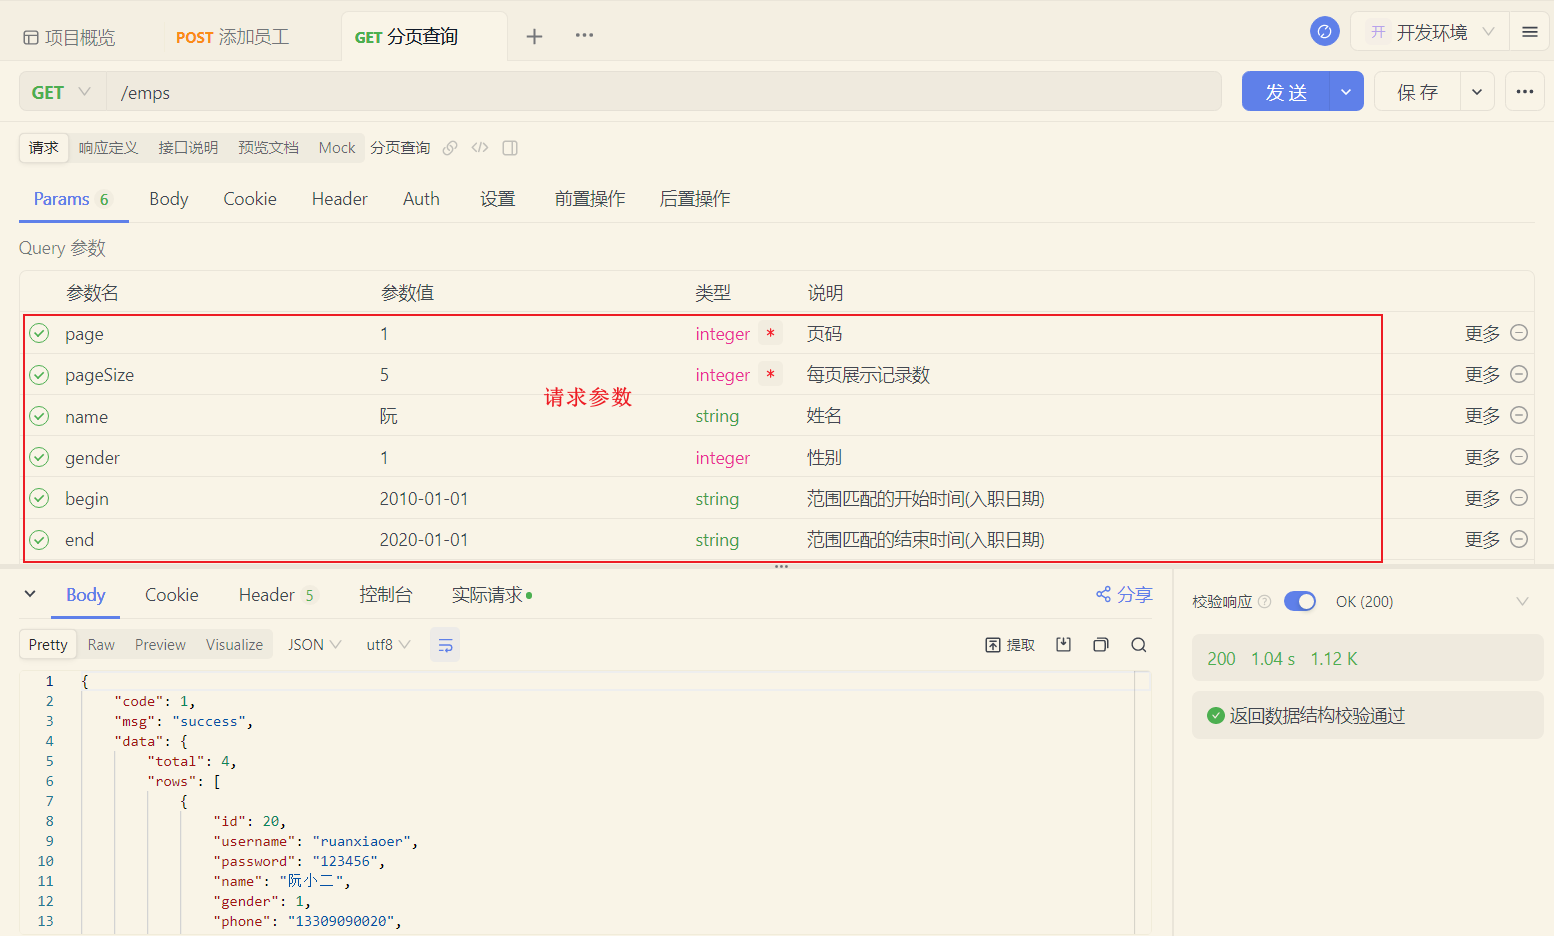

测试时，需要注意传递的查询条件，有些查询条件查不到数据的，因为数据库没有符合条件的记录。


#### 3.3.5 程序优化1

在上述分页条件查询中，请求参数比较多，有6个，如下所示：

- 请求参数：/emps?name=张&amp;gender=1&amp;begin=2007-09-01&amp;end=2022-09-01&amp;page=1&amp;pageSize=10

那我们在controller层方法中，接收请求参数的时候，直接在controller方法中声明这样6个参数即可，这样做，功能可以实现，但是不方便维护和管理。

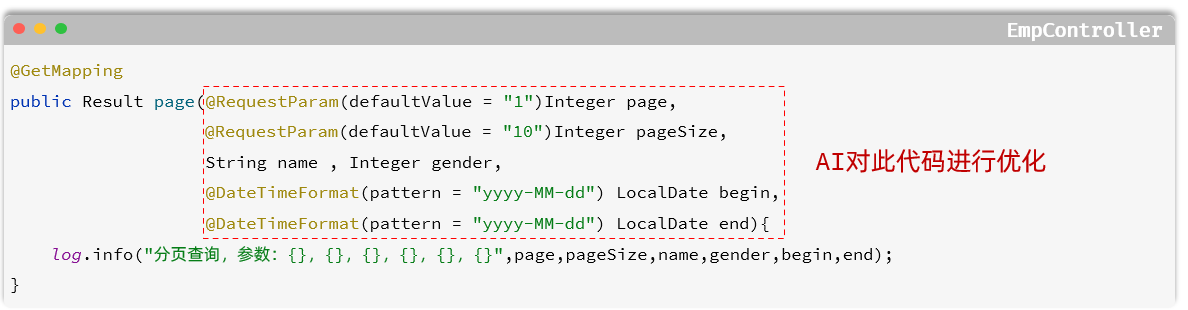

那接下来呢，我们就可以通过 <strong>通义零码</strong> AI辅助工具，对这一块儿的代码进行优化。 具体操作如下：

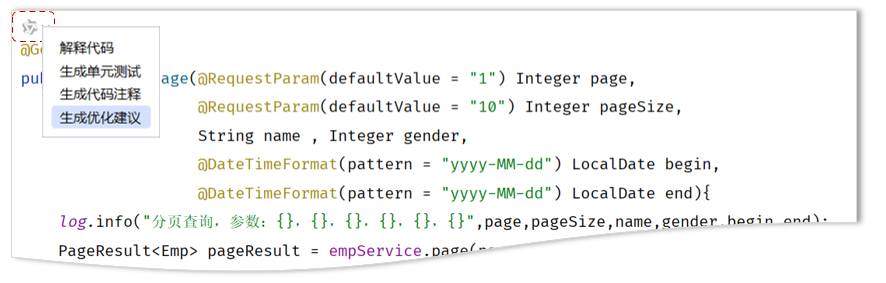

优化思路：定义一个实体类，来封装这几个请求参数。 <strong>【需要保证，</strong><strong>前端传递的请求参数和实体类的属性名是一样的</strong><strong>】</strong>

<strong>1). 定义实体类：EmpQueryParam</strong>

````java
package com.itheima.pojo;

import lombok.Data;
import org.springframework.format.annotation.DateTimeFormat;
import java.time.LocalDate;

@Data
public class EmpQueryParam {
    
    private Integer page = 1; //页码
    private Integer pageSize = 10; //每页展示记录数
    private String name; //姓名
    private Integer gender; //性别
    @DateTimeFormat(pattern = "yyyy-MM-dd")
    private LocalDate begin; //入职开始时间
    @DateTimeFormat(pattern = "yyyy-MM-dd")
    private LocalDate end; //入职结束时间
    
}
````

<strong>2). EmpController接收请求参数</strong>

````java
@GetMapping
public Result page(EmpQueryParam empQueryParam) {
    log.info("查询请求参数： {}", empQueryParam);
    PageResult pageResult = empService.page(empQueryParam);
    return Result.success(pageResult);
}
````

<strong>3). 修改EmpService接口方法</strong>

````java
public interface EmpService {
    /**
     * 分页查询
     */
    //PageResult page(Integer page, Integer pageSize, String name, Integer gender, LocalDate begin, LocalDate end);
    PageResult page(EmpQueryParam empQueryParam);
}
````

<strong>4). 修改EmpServiceImpl中的page方法</strong>

````java
@Service
public class EmpServiceImpl implements EmpService {

    @Autowired
    private EmpMapper empMapper;

    /*@Override
    public PageResult page(Integer page, Integer pageSize, String name, Integer gender, LocalDate begin, LocalDate end) {
        //1. 设置PageHelper分页参数
        PageHelper.startPage(page, pageSize);
        //2. 执行查询
        List<Emp> empList = empMapper.list(name, gender, begin, end);
        //3. 封装分页结果
        Page<Emp> p = (Page<Emp>) empList;
        return new PageResult(p.getTotal(), p.getResult());
    }*/

    public PageResult page(EmpQueryParam empQueryParam) {
        //1. 设置PageHelper分页参数
        PageHelper.startPage(empQueryParam.getPage(), empQueryParam.getPageSize());
        //2. 执行查询
        List<Emp> empList = empMapper.list(empQueryParam);
        //3. 封装分页结果
        Page<Emp> p = (Page<Emp>)empList;
        return new PageResult(p.getTotal(), p.getResult());
    }
}
````

<strong>5). 修改EmpMapper接口方法</strong>

````java
@Mapper
public interface EmpMapper {

    /**
     * 查询所有的员工及其对应的部门名称
     */
//    @Select("select e.*, d.name as deptName from emp e left join dept d on e.dept_id = d.id")
//    public List<Emp> list(String name, Integer gender, LocalDate begin, LocalDate end);
    
    /**
     * 根据查询条件查询员工
     */
    List<Emp> list(EmpQueryParam empQueryParam);
}
````

EmpMapper.xml 中的配置无需修改。

代码优化完毕之后，重新启动运行测试，依然正常运行：

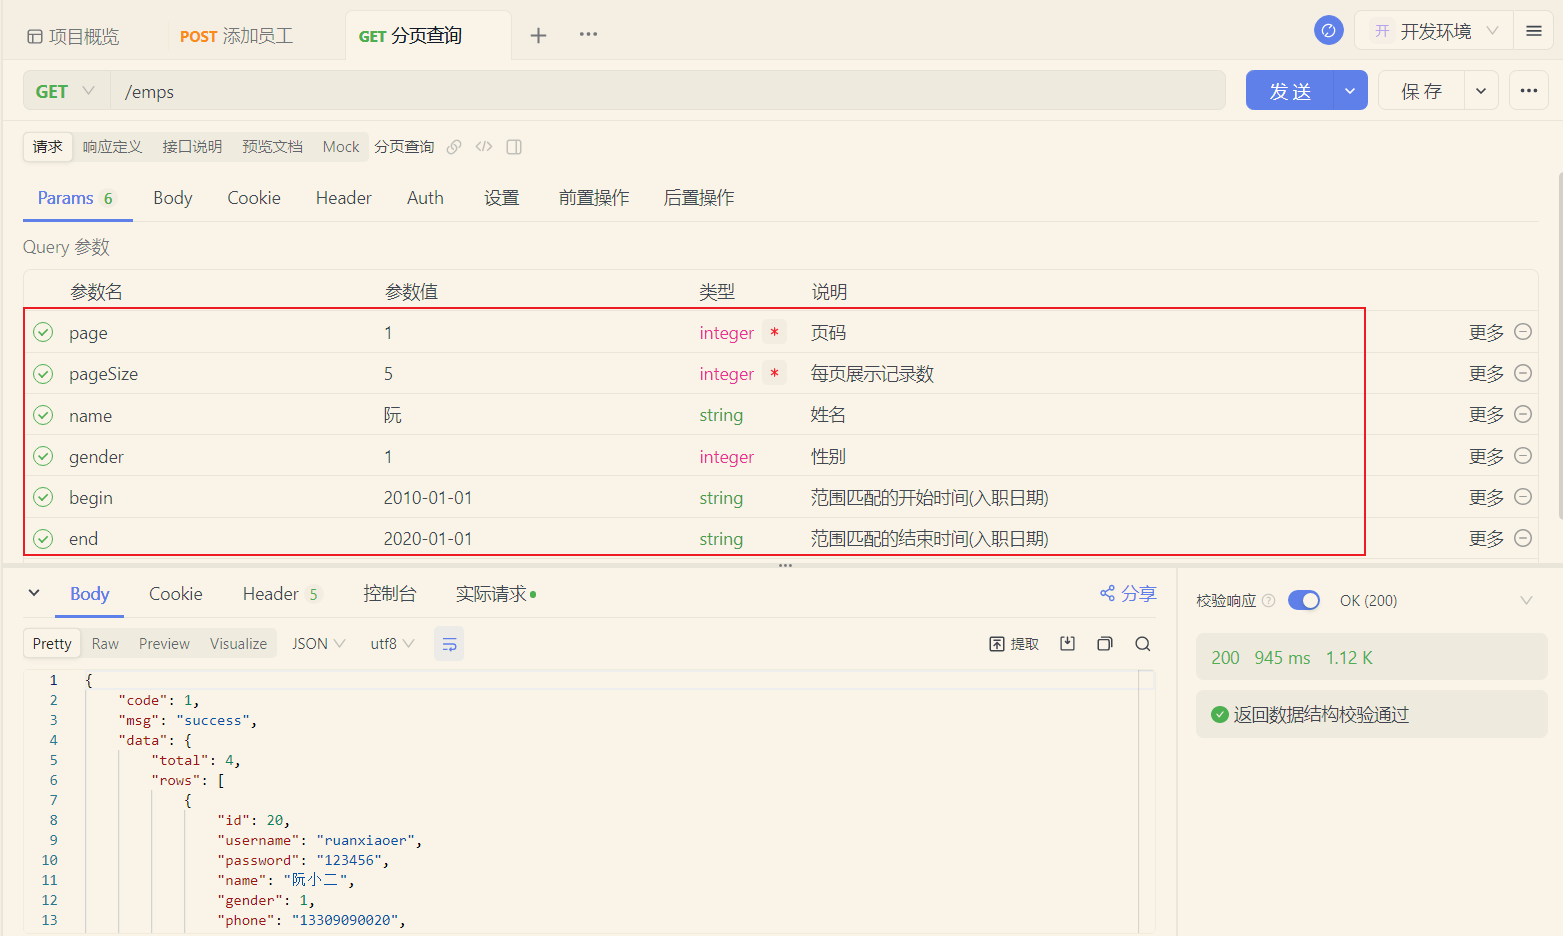

当我们在测试的时候，页码输入负数，查询是有问题的，查不到对应的数据了。

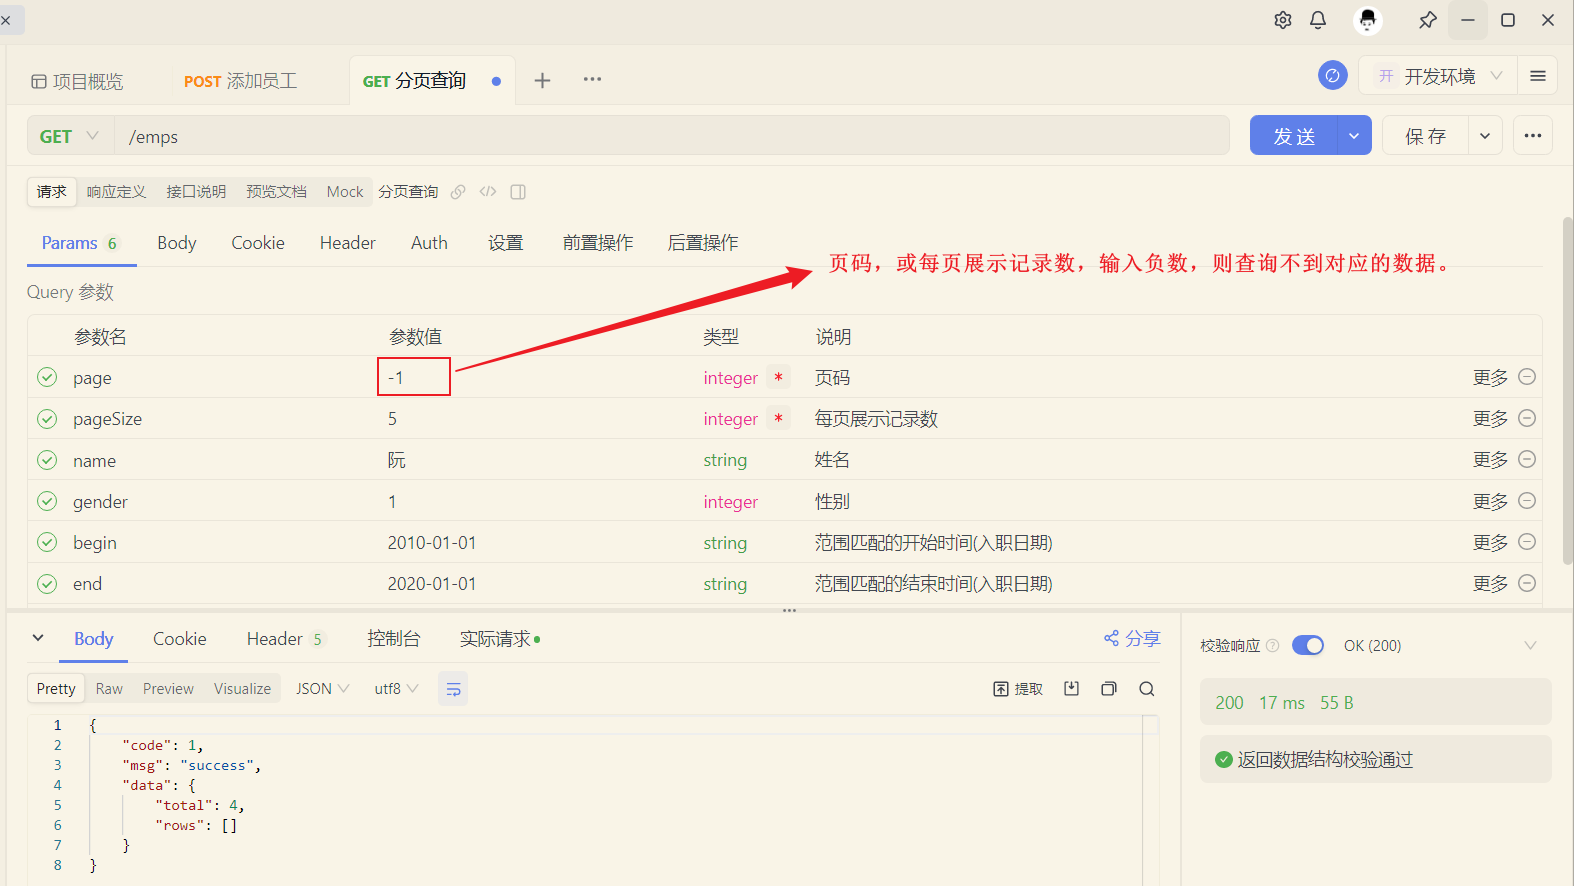

那其实在PageHelper中，我们可以通过合理化参数配置，来解决这个问题。直接在application.yml中，引入如下配置即可：

> **产品语义提醒：**`reasonable: true` 会把非法页码悄悄转成首页或末页，适合某些浏览场景，但会掩盖调用方错误。接口也可以显式拒绝 `page < 1` 或超大 `pageSize`，对超过最后一页返回空 `rows`。两种行为要在接口契约中选定并测试，不能同时假定。

````java
pagehelper:
  reasonable: true
  helper-dialect: mysql
````

reasonable：分页合理化参数，默认值为false。当该参数设置为true时，pageNum&lt;=0时会查询第一页，pageNum&gt;pages（超过总数时），会查询最后一页。默认false 时，直接根据参数进行查询。 

测试如下：

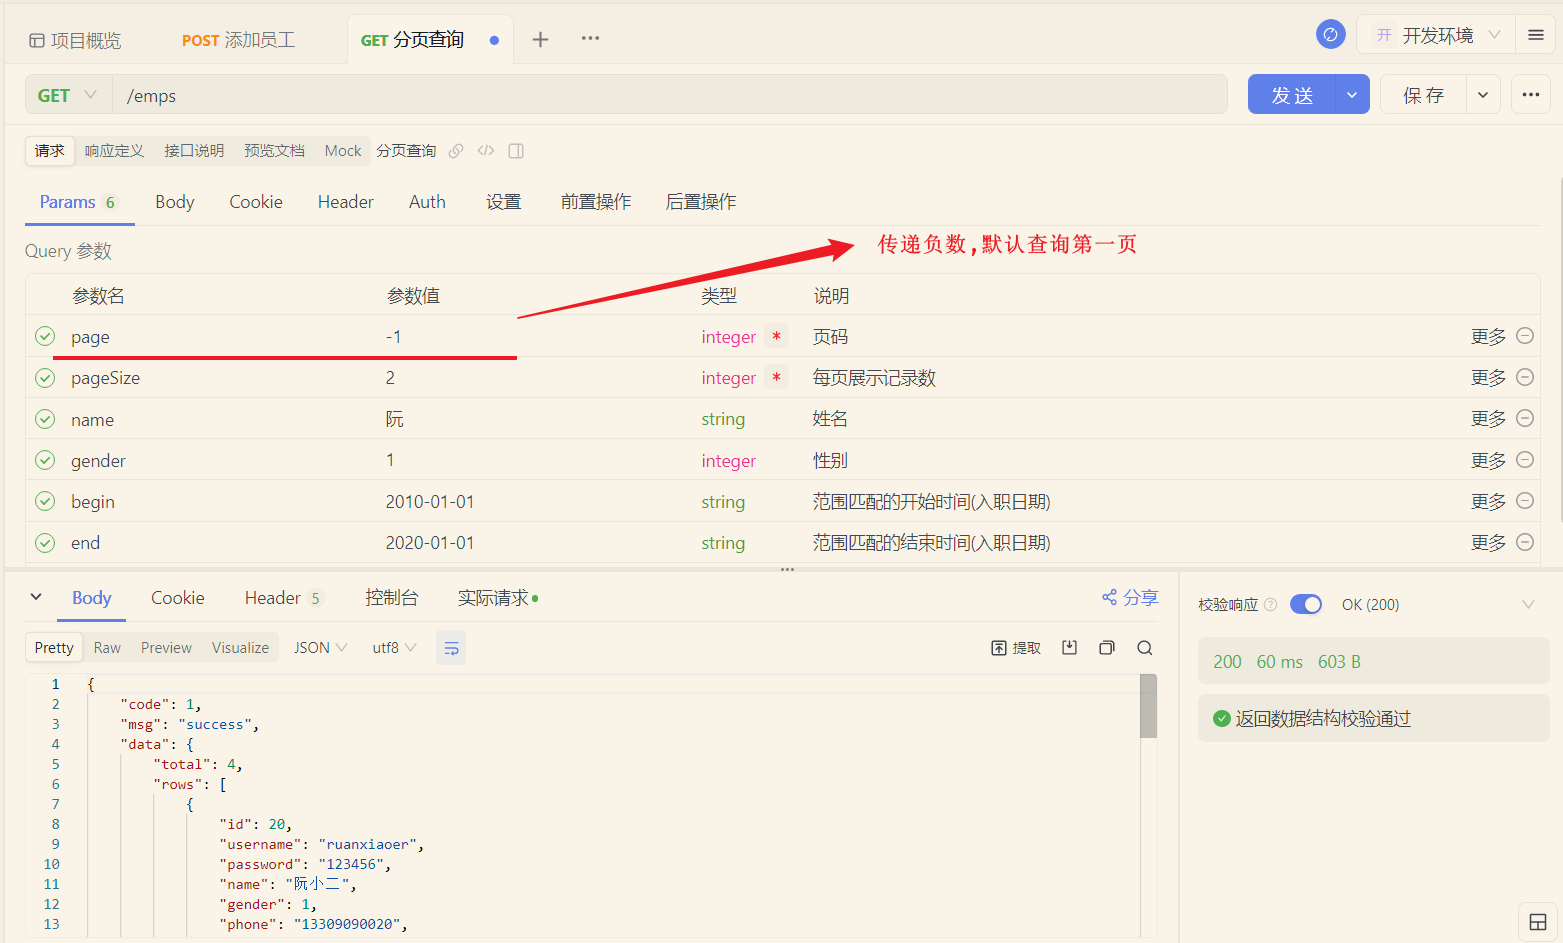


#### 3.3.6 程序优化2

当前，我们在查询的时候，Mapper映射配置文件中的SQL语句中，查询条件是写死的。 而我们在员工管理中，根据条件查询员工信息时，查询条件是可选的，可以输入也可以不输入。

> **动态条件细节：**讲义最终 XML 仅在 `begin` 和 `end` 同时有值时拼接 `BETWEEN`，若只传一个边界，该日期条件会被忽略。可分别用 `>= begin`、`<= end` 支持单边范围，或在参数校验时要求两端同时提供。无论采用哪种方案，`count` 与列表查询都必须使用同一筛选条件。

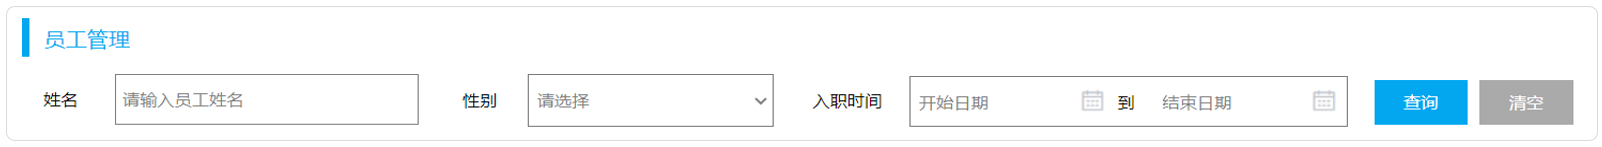

- 如果只输入 <strong>姓名</strong> 这个查询条件，则SQL语句中只根据name字段查询，SQL如下：

````sql
select e.*, d.name deptName from emp as e left join dept as d on e.dept_id = d.id where e.name like concat('%',#{name},'%')；
````

- 如果只输入 <strong>性别</strong> 这个查询条件，则SQL语句中只根据gender字段查询，SQL如下：

````sql
select e.*, d.name deptName from emp as e left join dept as d on e.dept_id = d.id where e.gender = #{gender}；
````

- 如果输入 <strong>姓名</strong> 和 <strong>性别 </strong>这两个查询条件，则SQL语句中要根据name、gender两个字段查询，SQL如下：

````sql
select e.*, d.name deptName from emp as e left join dept as d on e.dept_id = d.id
where e.name like concat('%',#{name},'%') and e.gender = #{gender}；
````

我们看到，这个SQL语句不应该是写死的，而应该根据用户输入的条件的变化而变化。 那这里呢，就要通过Mybatis中的<strong>动态SQL</strong>来实现。

<strong>所谓</strong><strong>动态SQL，指的就是随着用户的输入或外部的条件的变化而变化的SQL语句。</strong>

具体的代码实现如下：

````xml
<!--定义Mapper映射文件的约束和基本结构-->
<!DOCTYPE mapper
        PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.EmpMapper">
    <select id="list" resultType="com.itheima.pojo.Emp">
        select e.*, d.name deptName from emp as e left join dept as d on e.dept_id = d.id
        <where>
            <if test="name != null and name != ''">
                e.name like concat('%',#{name},'%')
            </if>
            <if test="gender != null">
                and e.gender = #{gender}
            </if>
            <if test="begin != null and end != null">
                and e.entry_date between #{begin} and #{end}
            </if>
        </where>
    </select>
</mapper>
````

在这里呢，我们用到了两个动态SQL的标签：<code>&lt;if&gt;</code>  <code>&lt;</code><code>where</code><code>&gt;</code>。 这两个标签的具体作用如下：

> <code>&lt;if&gt;</code>：判断条件是否成立，如果条件为true，则拼接SQL。
> 
> <code>&lt;where&gt;</code>：根据查询条件，来生成where关键字，并会自动去除条件前面多余的and或or。

代码优化完毕后，重新启动服务，测试如下：

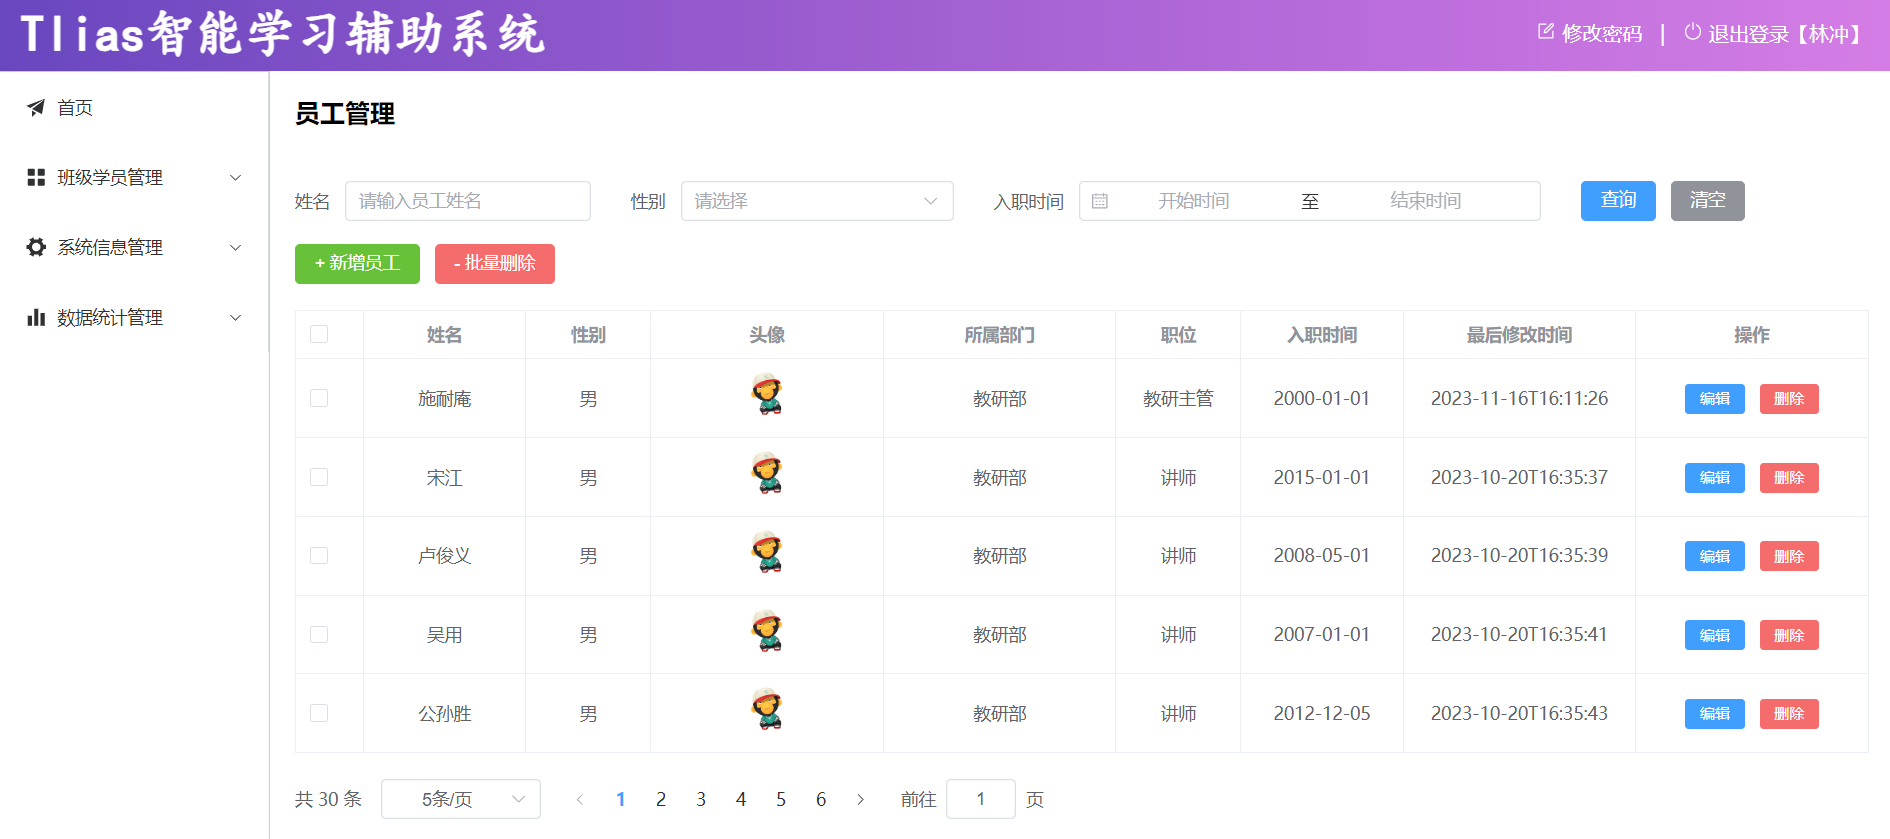

没有输入任何查询条件时，运行日志如下：

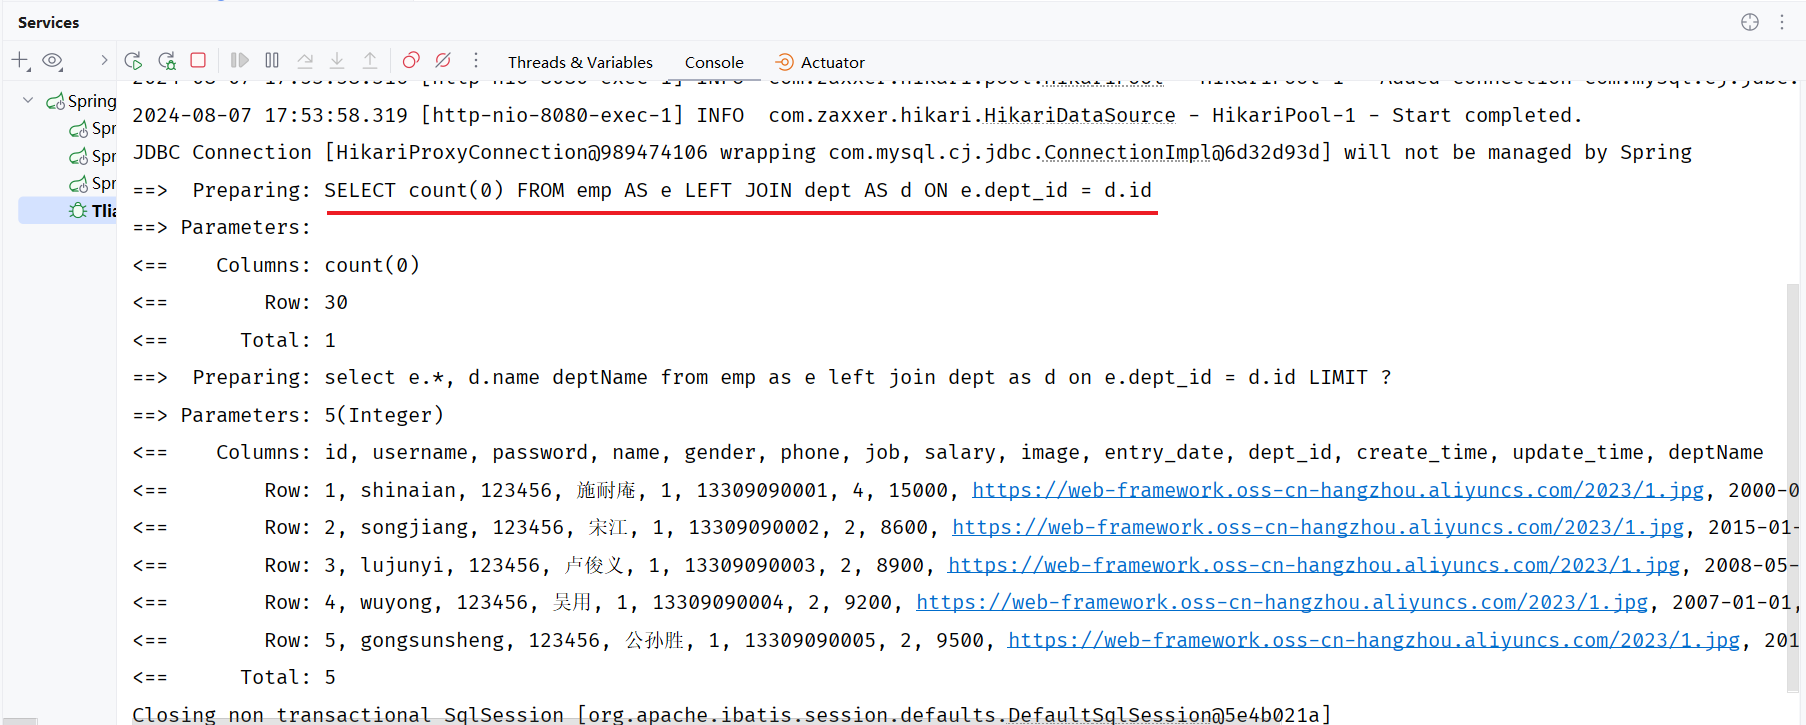

当我们输入姓名和性别时

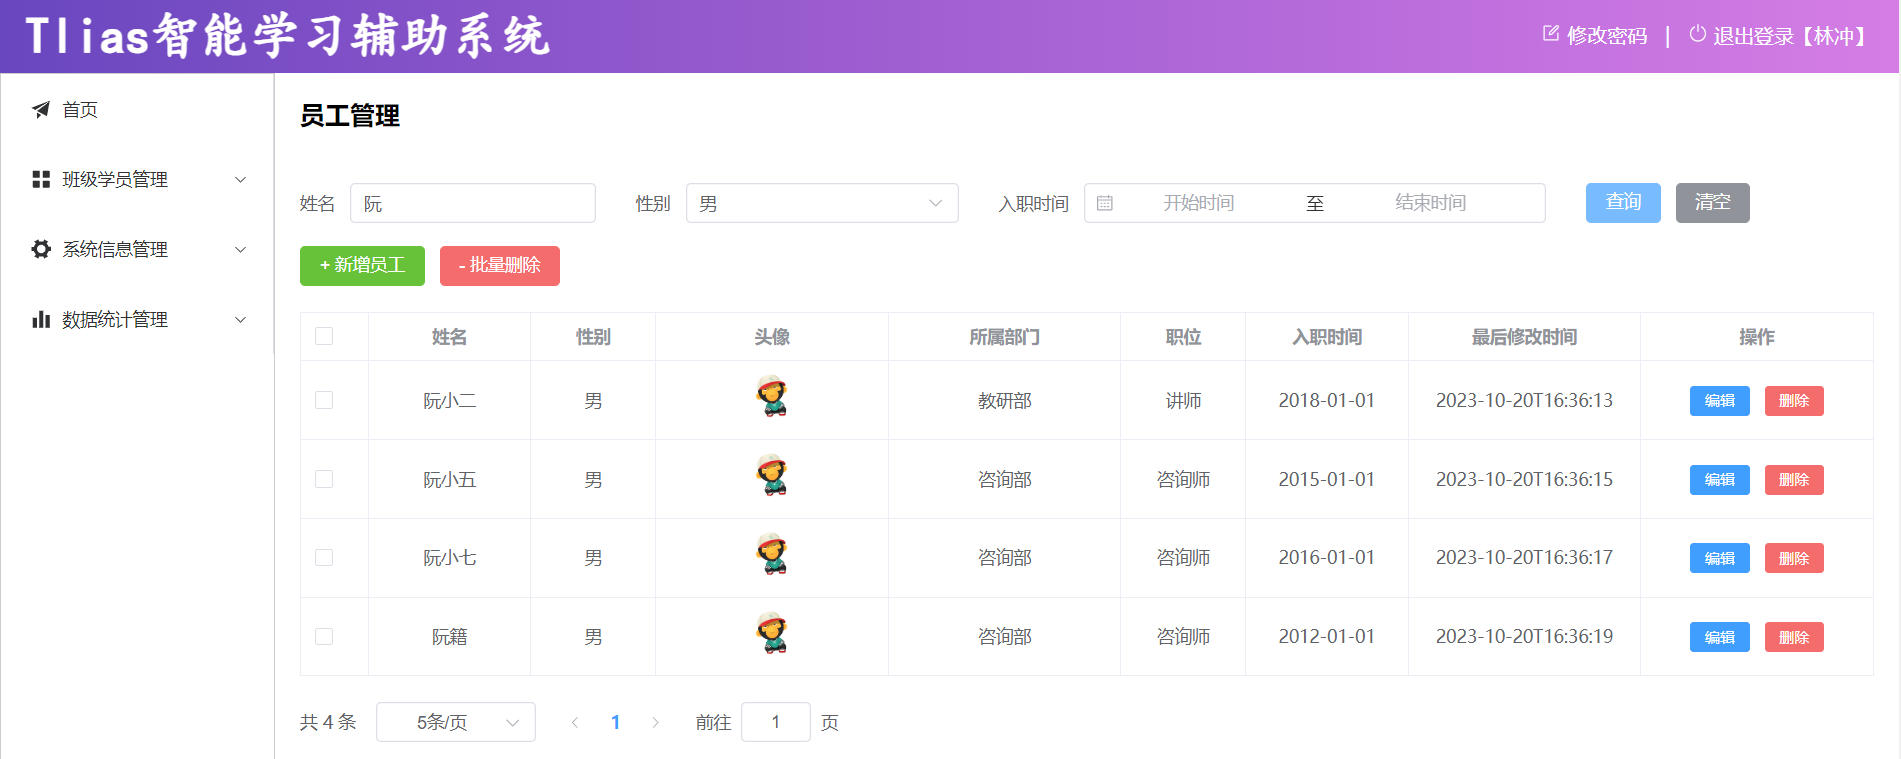

运行日志如下：

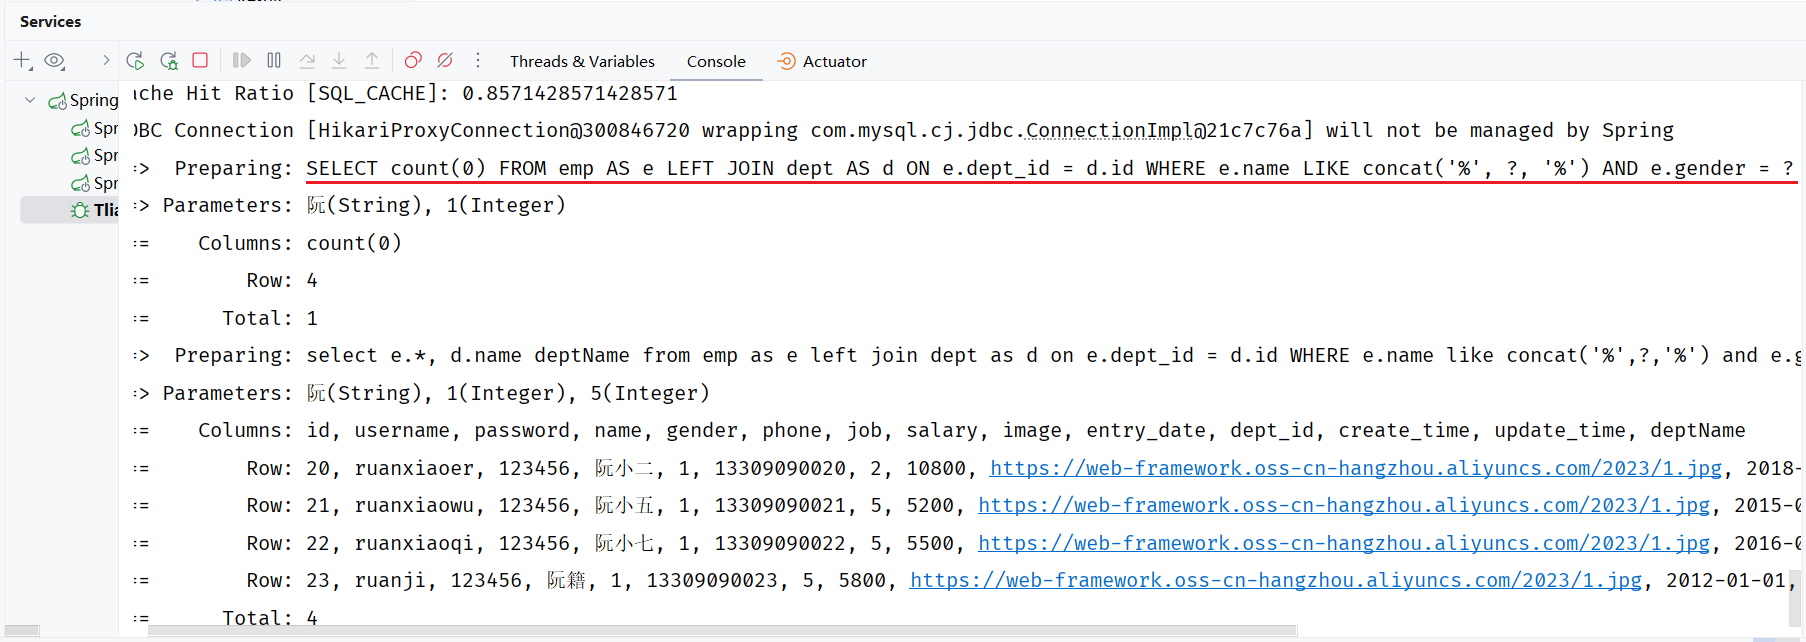

我们可以看到，当我们输入不同的搜索条件时，会动态的根据查询条件，动态拼接SQL语句。


## 4 补充：把本章知识串成一次请求

页面请求 `GET /emps?name=张&gender=1&begin=2007-09-01&end=2022-09-01&page=1&pageSize=10`。Spring MVC 把查询参数绑定到 `EmpQueryParam`；Service 校验分页和日期范围，接着让 PageHelper 对下一条 Mapper 查询分页；Mapper 的动态 SQL 按实际输入筛选 `emp`，并通过 `LEFT JOIN dept` 补出部门名。最终 `Result.data` 返回 `total` 和 `rows`。这一链路只实现**员工列表查询**，不包括后续章节的新增、修改和删除。

| 位置 | 要解决的问题 | 本章对应做法 |
| --- | --- | --- |
| 表关系 | 员工属于哪个部门？ | `emp.dept_id` 指向 `dept.id`；是否建物理外键单独决策 |
| 联表 | 无部门员工是否保留？ | 以 `emp` 为左表进行 `LEFT JOIN` |
| 筛选 | 条件没传时怎样处理？ | MyBatis `<where>` 和 `<if>` 只拼接有效条件 |
| 分页 | 页面与总数怎样一致？ | 同一筛选查询交给 PageHelper，检验生成的 count SQL |
| 安全 | 响应能否直接返回 Emp？ | 用列表 DTO 排除 `password` 等非页面字段 |

执行顺序不是“SQL 写完就行”：先核对 `/emps` 的参数及返回字段，再对 SQL 单独试算，随后检查 Mapper 映射、分页边界和浏览器联调。下面是一套**补充示例**，应放入第 07 章项目的对应文件；原讲义各阶段的同名类是演进片段，不能叠加编译。


## 5 补充：最终版条件分页查询

本节假定沿用第 07 章的 Spring Boot/MyBatis 项目、`Result` 统一返回体、已有 `dept` 表以及本章讲义的 `emp` 测试表。`pom.xml` 要加入与项目 Spring Boot 版本兼容的 PageHelper starter；课程展示的 `1.4.7` 仅用于复现课程环境，升级 Spring Boot 时应核对 starter 的官方兼容版本，不能直接复制版本号。`EmpMapper.xml` 路径为 `src/main/resources/mapper/EmpMapper.xml`，并配置 `mybatis.mapper-locations: classpath:mapper/*.xml` 与 `mybatis.configuration.map-underscore-to-camel-case: true`。

### 5.1 参数与返回对象

`EmpQueryParam.java`：GET 查询参数名必须与属性名一致。默认页码仅针对未传参数；显式传 `0`、负数或过大的 `pageSize` 仍需校验。

```java
@Data
public class EmpQueryParam {
    private Integer page = 1;
    private Integer pageSize = 10;
    private String name;
    private Integer gender;
    @DateTimeFormat(pattern = "yyyy-MM-dd")
    private LocalDate begin;
    @DateTimeFormat(pattern = "yyyy-MM-dd")
    private LocalDate end;
}
```

`EmpListItem.java` 只承载列表所需字段。若当前页面还需要其他字段，应先评估权限，再显式扩展；绝不加入 `password`。

```java
@Data
public class EmpListItem {
    private Integer id;
    private String username;
    private String name;
    private Integer gender;
    private Integer job;
    private String image;
    private LocalDate entryDate;
    private Integer deptId;
    private String deptName;
    private LocalDateTime updateTime;
}
```

`PageResult.java`：保持与课程接口 `total/rows` 一致。PageHelper 的总数类型为 `long`。

```java
@Data
@AllArgsConstructor
public class PageResult<T> {
    private long total;
    private List<T> rows;
}
```

以上片段省略 package 和 import；IDE 应导入 Lombok、`LocalDate`、`LocalDateTime`、`List` 与 Spring 的 `DateTimeFormat`。项目若不用 Lombok，改写等价的构造器、getter 和 setter 即可。


### 5.2 Controller、Service 和 Mapper

`EmpController.java`：边界错误返回 HTTP 400。`name` 的空白处理交给 Service；`begin > end` 直接拒绝，避免出现看似成功的空页。

```java
@RestController
@RequestMapping("/emps")
public class EmpController {
    private final EmpService empService;

    public EmpController(EmpService empService) { this.empService = empService; }

    @GetMapping
    public Result page(EmpQueryParam query) {
        if (query.getPage() == null || query.getPage() < 1 ||
            query.getPageSize() == null || query.getPageSize() < 1 || query.getPageSize() > 100) {
            throw new ResponseStatusException(HttpStatus.BAD_REQUEST, "page 或 pageSize 无效");
        }
        if (query.getBegin() != null && query.getEnd() != null &&
            query.getBegin().isAfter(query.getEnd())) {
            throw new ResponseStatusException(HttpStatus.BAD_REQUEST, "日期范围无效");
        }
        return Result.success(empService.page(query));
    }
}
```

`EmpService.java` / `EmpServiceImpl.java`：`startPage` 后立即调用目标 Mapper，不要夹入其他查询。`PageInfo` 从执行结果读取总数和当前页列表。

```java
public interface EmpService {
    PageResult<EmpListItem> page(EmpQueryParam query);
}

@Service
public class EmpServiceImpl implements EmpService {
    private final EmpMapper empMapper;

    public EmpServiceImpl(EmpMapper empMapper) { this.empMapper = empMapper; }

    @Override
    public PageResult<EmpListItem> page(EmpQueryParam query) {
        if (query.getName() != null) query.setName(query.getName().trim());
        PageHelper.startPage(query.getPage(), query.getPageSize());
        List<EmpListItem> list = empMapper.list(query);
        PageInfo<EmpListItem> info = new PageInfo<>(list);
        return new PageResult<>(info.getTotal(), info.getList());
    }
}
```

```java
@Mapper
public interface EmpMapper {
    List<EmpListItem> list(EmpQueryParam query);
}
```

示例依赖 `com.github.pagehelper.PageHelper/PageInfo`、Spring 的 `@Service/@RestController/@GetMapping/@RequestMapping`、`ResponseStatusException/HttpStatus` 等常规 import。现有工程的包名和 `Result` 类应与第 07 章一致；这里提供的是可拼接的最终类定义，不要与讲义前面的旧版 `EmpServiceImpl` 并存。


### 5.3 MyBatis XML 与验证顺序

`EmpMapper.xml` 列出允许返回的字段，`deptName` 用别名映射；`<where>` 会处理条件前的 `AND`。两个日期边界分别生效，既支持区间，也支持只传一端。`ORDER BY e.id DESC` 让普通分页在静态数据集上有确定顺序；并发新增时，偏移分页仍可能跨页重复，要求稳定游标时需另设计 keyset 分页。

```xml
<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.EmpMapper">
    <select id="list" resultType="com.itheima.pojo.EmpListItem">
        SELECT e.id, e.username, e.name, e.gender, e.job, e.image,
               e.entry_date, e.dept_id, e.update_time,
               d.name AS deptName
        FROM emp e
        LEFT JOIN dept d ON e.dept_id = d.id
        <where>
            <if test="name != null and name != ''">
                AND e.name LIKE CONCAT('%', #{name}, '%')
            </if>
            <if test="gender != null">
                AND e.gender = #{gender}
            </if>
            <if test="begin != null">
                AND e.entry_date &gt;= #{begin}
            </if>
            <if test="end != null">
                AND e.entry_date &lt;= #{end}
            </if>
        </where>
        ORDER BY e.id DESC
    </select>
</mapper>
```

`<`、`>` 必须在 XML 文本中写为 `&lt;`、`&gt;`；`#{...}` 是参数绑定，不能改成 `${...}` 拼接用户输入。Mapper 查询不要以分号结尾，让 PageHelper 能追加分页语句。以上 `namespace` 和 `resultType` 按 `com.itheima` 包名编写，改包名时同步修改。

按以下顺序验证，每一步都检查 `total` 与 `rows`：

1. `GET /emps?page=1&pageSize=5`：无筛选，`rows` 最多 5 条；课程样本中无部门员工仍出现且 `deptName=null`。
2. `GET /emps?name=阮&gender=1&page=1&pageSize=10`：姓名模糊匹配、性别精确匹配，列表和总数用同一条件。
3. `GET /emps?begin=2015-01-01` 与 `GET /emps?end=2010-12-31`：单边日期条件不能被静默忽略。
4. `GET /emps?page=0`、`pageSize=1000` 和 `begin=2022-01-01&end=2000-01-01`：得到 400；日期格式错误也应按 400 处理。
5. 检查 JSON 的每条 `rows`：有 `deptName`，没有 `password`；再对照 SQL 日志确认 `count`、`LIMIT` 与排序生效。

这里的 SQL 和 Java 供在已有项目中跟练，本次笔记整理没有在本机 Maven/MySQL 环境中联调。课程测试数据只用于学习，不能当生产账号、密码或真实员工数据使用。


**面试提示**：给定“员工可能没有部门，列表要按姓名、性别、入职日期过滤并分页”的需求，先解释 `emp.dept_id` 与 `dept.id` 的一对多关系；再说明为什么选择 `LEFT JOIN`，`ON` 与 `WHERE` 对空部门行的影响；最后说明动态 SQL、`ORDER BY`、`LIMIT`/PageHelper、`total` 与 `rows` 如何保持同一筛选语义。若被追问物理外键，按单库一致性和跨库约束的实际边界作答，不把“逻辑外键”说成自动具备数据库约束。


补充核对资料：[MySQL 外键约束](https://dev.mysql.com/doc/refman/8.0/en/create-table-foreign-keys.html)、[MySQL JOIN](https://dev.mysql.com/doc/refman/8.0/en/join.html)、[MyBatis 动态 SQL](https://mybatis.org/mybatis-3/dynamic-sql.html)、[PageHelper 官方文档](https://pagehelper.github.io/)、[Spring MVC 参数绑定](https://docs.spring.io/spring-framework/reference/web/webmvc/mvc-controller/ann-methods/modelattrib-method-args.html)。课程版本用于复现讲义，不代表当前最新版本。
